# v7.1b Reject-Class NIDS with Verifiable XAI - CIC-UNSW-NB15-2024

Two-stage hierarchical detector with a **Stage-B reject class**, an alpha-diverse 7-member ensemble
and a learned per-class combiner, on the **full CICFlowMeter release** (3,540,241 flows, Benign
~97.5%) - identical to `final_model_v7_1_reject_stages.ipynb` up to 5.3 - **plus a verified
explainability layer** (5.4-5.11) and per-alert explanations at inference (7).

**Baselines to beat (macro-F1):**

| Model | macro-F1 | accuracy |
|---|---|---|
| Flat XGBoost, `balanced` weights (curated file) | 0.5807 | 0.8949 |
| v7 two-stage, 9-class Stage B (full release) | 0.6601 | 0.9799 |
| v7.1 + reject class (reference) | 0.6843 | 0.9875 |
| **v7.1b + end-to-end combiner objective (target)** | **0.6874** | 0.9866 |

**Why the XAI is built the way it is.** SHAP on a NIDS ensemble is not new - CyberAdaptAI already
reports it. What the literature lacks is explanations anyone can *check*: CyberAdaptAI's SHAP table
cannot be SHAP output (its columns sum to exactly 1.00). So every explanation here carries its own
verification - additivity residuals, a second independent implementation, and a proof that the
explanation reproduces the deployed decision. See `results/xai_treeshap/` for the pre-registered run.

**Runtime** ~15 min with the three caches present; ~50 min cold.
**Kernel** must be the `ai4beg` conda env (sklearn / xgboost / imblearn / **shap 0.51**).
**Requires** `cache_oof_v7_full.npz` from `final_model_v7_full.ipynb` for the baseline arm in 6.1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, gc, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)
import xgboost as xgb
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import shap
from scipy.stats import spearmanr, rankdata
from math import factorial

CFM = Path("Resource/CICFlowMeter_out.csv")
RS, EPS = 42, 1e-6

# Official label mapping. Attack families are alphabetical, Benign = 0.
LABELS = {
    0: "Benign", 1: "Analysis", 2: "Backdoor", 3: "DoS", 4: "Exploits",
    5: "Fuzzers", 6: "Generic", 7: "Reconnaissance", 8: "Shellcode", 9: "Worms",
}
CAT = {v: k for k, v in LABELS.items()}
NAMES = [LABELS[i] for i in range(10)]

print("Dataset:", CFM, "| exists:", CFM.exists())
print("shap %s | xgboost %s | numpy %s" % (shap.__version__, xgb.__version__, np.__version__))

Dataset: Resource\CICFlowMeter_out.csv | exists: True
shap 0.51.0 | xgboost 3.3.0 | numpy 2.2.6


## 1. Data Collection
_Sources & Quality_

The full release ships as **one** file with metadata columns in front (`Flow ID`, `Src IP`,
`Src Port`, `Dst IP`, `Dst Port`, `Protocol`, `Timestamp`), then the 76 CICFlowMeter features, then a
string `Label`. Unlike the curated two-file version there is no row-alignment risk.

Two metadata columns are kept as **features**: `Dst Port` and `Protocol`. These carry service
identity, which the ablation in `results/cic_unsw_svc/` measured as the single largest gain in the
project (+0.098 macro-F1). `Src IP` / `Dst IP` / `Timestamp` are deliberately **excluded** - they
identify the machine, not the behaviour, and would let the model memorise the testbed.

In [2]:
t0 = time.time()

hdr = pd.read_csv(CFM, nrows=0).columns.tolist()
FEAT76 = hdr[7:-1]                      # skip the 7 metadata cols, drop the trailing Label

dtypes = {c: np.float32 for c in FEAT76}
dtypes["Dst Port"] = np.int32
dtypes["Protocol"] = np.int16

df = pd.read_csv(CFM, usecols=["Dst Port", "Protocol"] + FEAT76 + ["Label"], dtype=dtypes)

print("Metadata columns available :", hdr[:7])
print("Feature columns            :", len(FEAT76))
print("Loaded shape               :", df.shape, "(%.0fs)" % (time.time() - t0))
print("Excluded on purpose        : Flow ID, Src IP, Dst IP, Src Port, Timestamp")
df.head()

Metadata columns available : ['Flow ID', 'Src IP', 'Src Port', 'Dst IP', 'Dst Port', 'Protocol', 'Timestamp']
Feature columns            : 76
Loaded shape               : (3540241, 79) (17s)
Excluded on purpose        : Flow ID, Src IP, Dst IP, Src Port, Timestamp


,Dst Port,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,6,214392.0,9.0,21.0,388.0,24564.0,194.0,0.0,43.111111,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Exploits
1,80,6,2376792.0,9.0,3.0,752.0,0.0,188.0,0.0,83.555557,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Reconnaissance
2,5555,6,131350.0,10.0,3.0,7564.0,0.0,1460.0,0.0,756.400024,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Exploits
3,80,6,164796.0,6.0,3.0,770.0,0.0,385.0,0.0,128.333328,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DoS
4,3000,6,163418.0,6.0,3.0,400.0,0.0,200.0,0.0,66.666664,...,20.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Generic


## 2. Data Preparation
_Clean & Transform_

### 2.1 Check for duplicates

Duplicates are the single biggest correctness trap in this dataset. Check on **features + port +
protocol + label together**, so only genuinely identical rows are counted.

In [3]:
n_dup = df.duplicated().sum()
print("Rows            :", len(df))
print("Duplicate rows  :", n_dup)
print("Duplicate share : %.2f%%" % (n_dup / len(df) * 100))

# Feature-only duplicates minus feature+label duplicates = rows whose identical feature vector
# carries a CONFLICTING label. That gap is the label-ambiguity floor.
n_dup_feat = df.drop(columns=["Label"]).duplicated().sum()
print("\nFeature-only duplicates : %d" % n_dup_feat)
print("Conflicting-label rows  : %d (%.3f%%)"
      % (n_dup_feat - n_dup, (n_dup_feat - n_dup) / len(df) * 100))

Rows            : 3540241
Duplicate rows  : 933438
Duplicate share : 26.37%



Feature-only duplicates : 933961
Conflicting-label rows  : 523 (0.015%)


### 2.2 Drop duplicates

Drop **before** the split, so no flow can appear on both sides of it. Leaving them in is the leakage
that produces the near-100% scores common in this literature.

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
y = df["Label"].map(CAT).astype(int).values

print("After dropping duplicates :", df.shape)
print("Duplicates remaining      :", df.duplicated().sum())
print("Labels mapped to 0-9      :", np.array_equal(np.unique(y), np.arange(10)))

After dropping duplicates : (2606803, 79)


Duplicates remaining      : 0
Labels mapped to 0-9      : True


### 2.3 Class distribution

The full release sits at the **real base rate**: Benign is ~97.5%, not the curated file's 80%. This
is what makes the problem realistic and plain accuracy useless - and it is the reason the reject
class in 4.2 exists at all.

                class    count  percent
label                                  
0              Benign  2525314  96.8740
1            Analysis      385   0.0148
2            Backdoor      452   0.0173
3                 DoS     4418   0.1695
4            Exploits    30925   1.1863
5             Fuzzers    26433   1.0140
6             Generic     4496   0.1725
7      Reconnaissance    12035   0.4617
8           Shellcode     2102   0.0806
9               Worms      243   0.0093

Imbalance ratio (Benign : Worms) = 10392 : 1


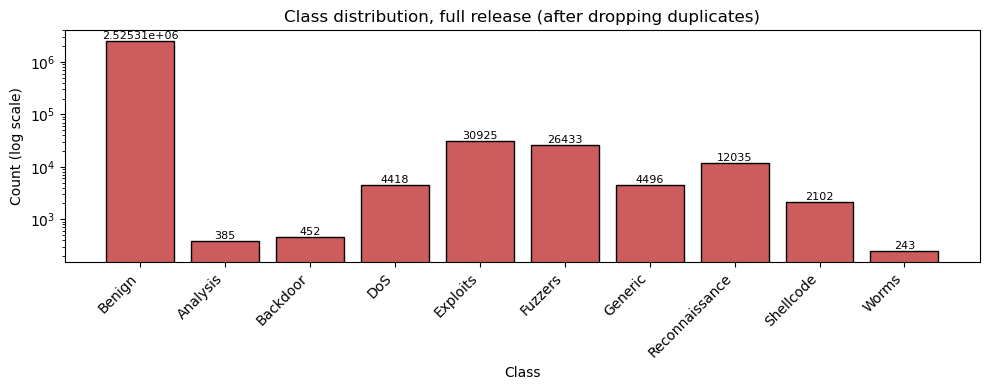

In [5]:
counts = pd.Series(y).value_counts().sort_index()
dist = pd.DataFrame({
    "class":   [LABELS[i] for i in counts.index],
    "count":   counts.values,
    "percent": (counts.values / counts.sum() * 100).round(4),
}, index=counts.index)
dist.index.name = "label"
print(dist.to_string())
print("\nImbalance ratio (Benign : Worms) = %.0f : 1" % (counts[0] / counts[9]))

plt.figure(figsize=(10, 4))
bars = plt.bar([LABELS[i] for i in counts.index], counts.values,
               color="indianred", edgecolor="black")
plt.yscale("log")
plt.title("Class distribution, full release (after dropping duplicates)")
plt.xlabel("Class")
plt.ylabel("Count (log scale)")
plt.xticks(rotation=45, ha="right")
plt.bar_label(bars, fontsize=8)
plt.tight_layout()
plt.show()

### 2.4 Variance check

A feature with a single unique value carries no information. Surface the constant columns here; they
are dropped in 2.6.

In [6]:
Xraw = df[FEAT76]
nunique = Xraw.nunique()
zero_var_cols = nunique[nunique <= 1].index.tolist()

print("Total features           : %d" % Xraw.shape[1])
print("Zero-variance (constant) : %d\n" % len(zero_var_cols))
for c in zero_var_cols:
    print("  %-26s -> constant value = %s" % (c, Xraw[c].iloc[0]))

FULL = Xraw.drop(columns=zero_var_cols)
print("\nRemaining after variance prune: %d" % FULL.shape[1])

Total features           : 76
Zero-variance (constant) : 9

  Bwd PSH Flags              -> constant value = 0.0
  Fwd URG Flags              -> constant value = 0.0
  Bwd URG Flags              -> constant value = 0.0
  URG Flag Count             -> constant value = 0.0
  CWR Flag Count             -> constant value = 0.0
  ECE Flag Count             -> constant value = 0.0
  Fwd Bytes/Bulk Avg         -> constant value = 0.0
  Fwd Packet/Bulk Avg        -> constant value = 0.0
  Fwd Bulk Rate Avg          -> constant value = 0.0

Remaining after variance prune: 67


### 2.5 Correlation

Highly correlated features add redundancy without new signal. Plot the matrix, then list pairs above
the threshold as drop candidates.

This prune is **label-free**, so it may legitimately run before the split - unlike anything that
touches `y`.

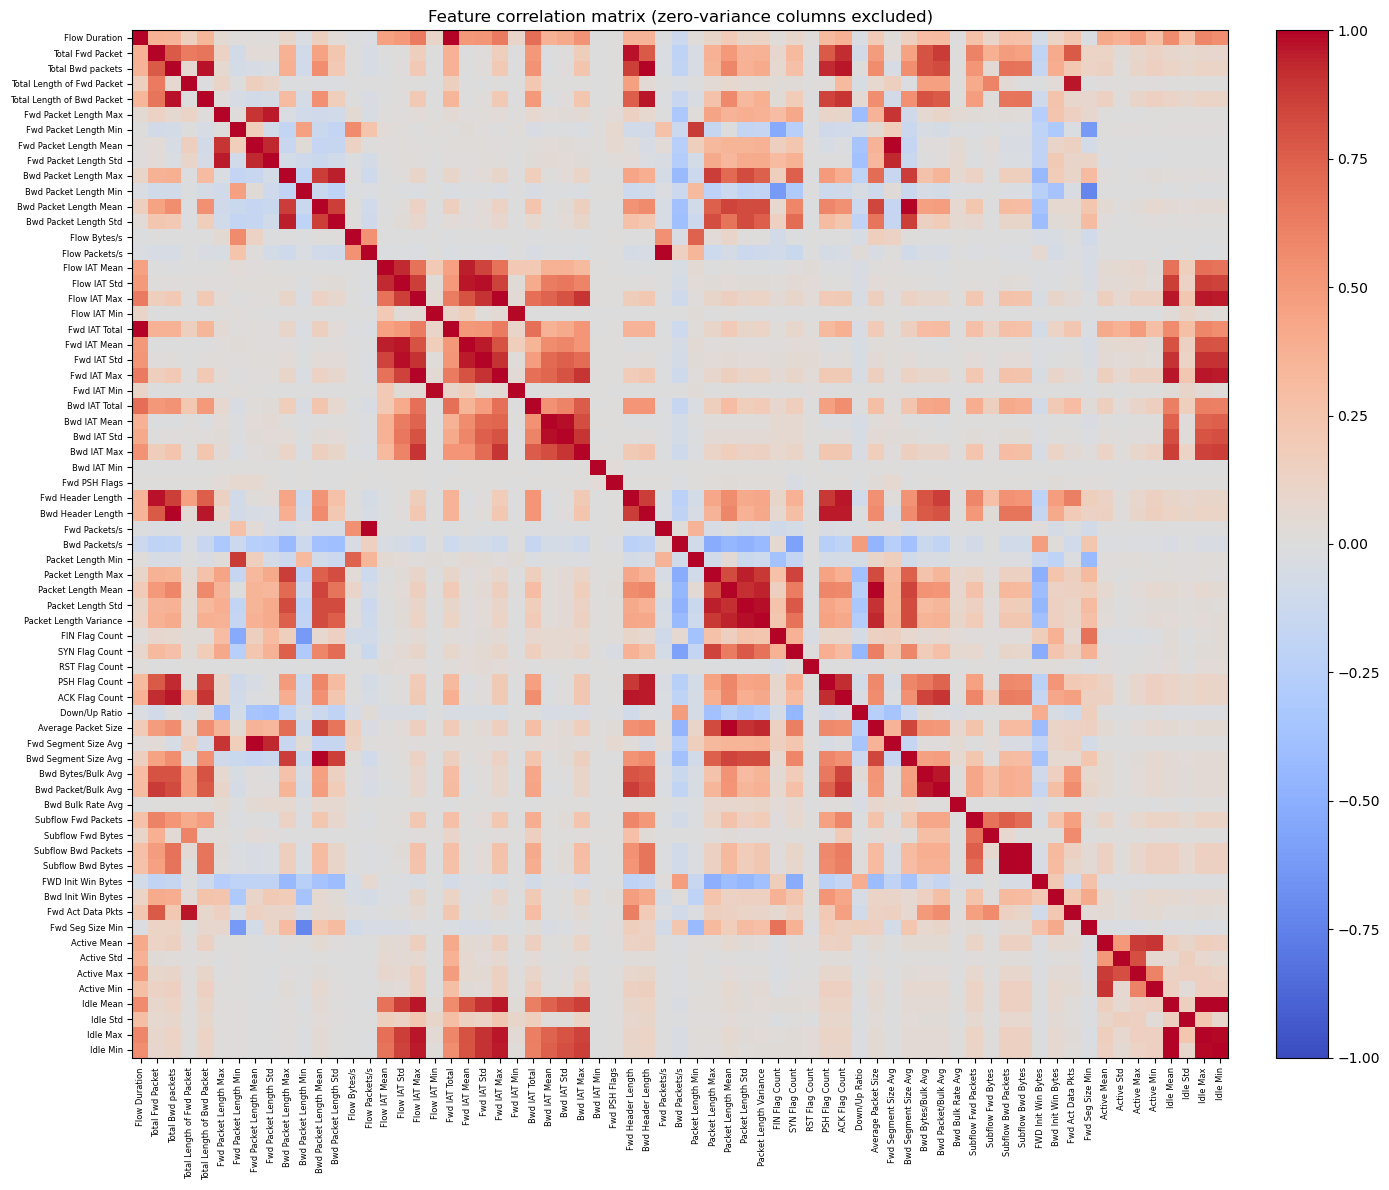

In [7]:
corr = FULL.corr()

plt.figure(figsize=(14, 12))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
plt.yticks(range(len(corr)), corr.columns, fontsize=6)
plt.title("Feature correlation matrix (zero-variance columns excluded)")
plt.tight_layout()
plt.show()

In [8]:
THRESHOLD = 0.95

upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "abs_corr"})
)
high_pairs = high_pairs[high_pairs["abs_corr"] >= THRESHOLD].sort_values(
    "abs_corr", ascending=False
).reset_index(drop=True)

print("Highly correlated pairs (|r| >= %.2f): %d\n" % (THRESHOLD, len(high_pairs)))
print(high_pairs.head(25).to_string(index=False))
if len(high_pairs) > 25:
    print("  ... %d more" % (len(high_pairs) - 25))

Highly correlated pairs (|r| >= 0.95): 34

                 feature_1                  feature_2  abs_corr
    Bwd Packet Length Mean       Bwd Segment Size Avg  1.000000
    Fwd Packet Length Mean       Fwd Segment Size Avg  1.000000
             Flow Duration              Fwd IAT Total  0.999126
                 Idle Mean                   Idle Min  0.997991
        Packet Length Mean        Average Packet Size  0.997496
              Flow IAT Max                Fwd IAT Max  0.997295
                 Idle Mean                   Idle Max  0.996373
       Subflow Bwd Packets          Subflow Bwd Bytes  0.995443
         Total Bwd packets          Bwd Header Length  0.994068
            Flow Packets/s              Fwd Packets/s  0.992913
                  Idle Max                   Idle Min  0.989561
              Flow IAT Min                Fwd IAT Min  0.987874
              Flow IAT Std                Fwd IAT Std  0.979017
         Packet Length Std     Packet Length Variance  0.9783

### 2.6 Drop uninformative & redundant features

Act on the evidence from 2.4 and 2.5: for each highly-correlated pair keep the first column and drop
the later one.

Note this leaves a **pruned base** (`BASE`), but 2.7 builds its derived features from the
**unpruned** set (`FULL`). A column dropped here for being linearly redundant can still contribute
its non-linear part as a ratio - the prune removes duplicated information, not the underlying
measurement.

In [9]:
redundant_cols = [c for c in upper.columns if (upper[c] >= THRESHOLD).any()]
BASE = FULL.drop(columns=redundant_cols)

print("Zero-variance dropped (2.4) : %d" % len(zero_var_cols))
print("Redundant |r|>=%.2f dropped  : %d" % (THRESHOLD, len(redundant_cols)))
print("   e.g.", redundant_cols[:8], "..." if len(redundant_cols) > 8 else "")
print("\nBASE features remaining     : %d  (from %d)" % (BASE.shape[1], len(FEAT76)))

Zero-variance dropped (2.4) : 9
Redundant |r|>=0.95 dropped  : 24
   e.g. ['Total Length of Bwd Packet', 'Fwd Packet Length Std', 'Bwd Packet Length Std', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min'] ...

BASE features remaining     : 43  (from 76)


### 2.7 Engineered ratio features

31 scale-free columns: forward/backward ratios, bytes-per-packet, coefficients of variation for
inter-arrival times and packet lengths, **flags expressed as fractions of packets**, header overhead,
duration-normalised activity, and the initial-window ratio.

The point is scale-invariance. A raw byte count depends on how long the flow ran; a ratio does not,
so it transfers to traffic the model has not seen. `feature_engineering.ipynb` measured this block at
+0.0101 macro-F1 and a gate-precision lift of 0.9175 -> 0.9267.

Built from `FULL` (pre-prune), as noted in 2.6. Written as a function because 5.10 re-derives
them after perturbing the raw columns of test flows.

In [10]:
def safe(a, b):
    """Ratio guarded against division by zero and inf, returned as 0.0."""
    return (a / (b + EPS)).replace([np.inf, -np.inf], 0.0).fillna(0.0)

def derive(F):
    """The 31 engineered columns, computed from raw CICFlowMeter columns."""
    g = lambda c: F[c] if c in F.columns else pd.Series(0.0, index=F.index)

    fpk, bpk = g("Total Fwd Packet"), g("Total Bwd packets")
    fby, bby = g("Total Length of Fwd Packet"), g("Total Length of Bwd Packet")
    tot_pk, tot_by = fpk + bpk, fby + bby

    d = {}
    d["r_pkt_fwd_bwd"]  = safe(fpk, bpk);          d["r_byte_fwd_bwd"] = safe(fby, bby)
    d["asym_pkt"]       = safe(fpk - bpk, tot_pk); d["asym_byte"]      = safe(fby - bby, tot_by)
    d["bpp_fwd"]        = safe(fby, fpk);          d["bpp_bwd"]        = safe(bby, bpk)
    d["bpp_flow"]       = safe(tot_by, tot_pk);    d["r_bpp"]          = safe(d["bpp_fwd"], d["bpp_bwd"])
    d["cv_flow_iat"]    = safe(g("Flow IAT Std"), g("Flow IAT Mean"))
    d["cv_fwd_iat"]     = safe(g("Fwd IAT Std"), g("Fwd IAT Mean"))
    d["cv_bwd_iat"]     = safe(g("Bwd IAT Std"), g("Bwd IAT Mean"))
    d["iat_span_rel"]   = safe(g("Flow IAT Max") - g("Flow IAT Min"), g("Flow IAT Mean"))
    d["cv_fwd_len"]     = safe(g("Fwd Packet Length Std"), g("Fwd Packet Length Mean"))
    d["cv_bwd_len"]     = safe(g("Bwd Packet Length Std"), g("Bwd Packet Length Mean"))
    d["cv_pkt_len"]     = safe(g("Packet Length Std"), g("Packet Length Mean"))
    d["fwd_len_span_rel"] = safe(g("Fwd Packet Length Max") - g("Fwd Packet Length Min"),
                                 g("Fwd Packet Length Mean"))
    d["bwd_len_span_rel"] = safe(g("Bwd Packet Length Max") - g("Bwd Packet Length Min"),
                                 g("Bwd Packet Length Mean"))
    for flag in ("FIN", "SYN", "RST", "PSH", "ACK"):
        d["frac_" + flag] = safe(g(flag + " Flag Count"), tot_pk)
    d["r_syn_fin"]         = safe(g("SYN Flag Count"), g("FIN Flag Count"))
    d["hdr_per_pkt_fwd"]   = safe(g("Fwd Header Length"), fpk)
    d["hdr_per_pkt_bwd"]   = safe(g("Bwd Header Length"), bpk)
    d["payload_share_fwd"] = safe(fby - g("Fwd Header Length"), fby)
    dur = g("Flow Duration")
    d["active_share"]   = safe(g("Active Mean"), dur)
    d["idle_share"]     = safe(g("Idle Mean"), dur)
    d["r_active_idle"]  = safe(g("Active Mean"), g("Idle Mean"))
    d["dur_per_pkt"]    = safe(dur, tot_pk)
    d["r_init_win"]     = safe(g("FWD Init Win Bytes"), g("Bwd Init Win Bytes"))
    return pd.DataFrame(d, index=F.index).replace([np.inf, -np.inf], 0.0).fillna(0.0).astype(np.float32)

DER = derive(FULL)
dz = DER.nunique()
DER = DER.drop(columns=dz[dz <= 1].index.tolist())
DER_COLS = list(DER.columns)

print("Derived features built : %d\n" % DER.shape[1])
print(DER.describe().T[["mean", "std", "min", "max"]].head(8).to_string())


Derived features built : 31



                        mean           std       min           max
r_pkt_fwd_bwd   4.366547e+04  2.435625e+06  0.002500  9.300000e+08
r_byte_fwd_bwd  3.625034e+08  1.855387e+10  0.000000  1.113710e+13
asym_pkt       -1.025368e-01  2.051161e-01 -0.995012  1.000000e+00
asym_byte      -2.457903e-01  5.802824e-01 -1.000000  1.000000e+00
bpp_fwd         6.759241e+01  1.671927e+02  0.000000  1.473999e+03
bpp_bwd         2.429711e+02  3.440890e+02  0.000000  1.448000e+03
bpp_flow        1.718940e+02  2.124223e+02  0.000000  1.473999e+03
r_bpp           1.722853e+07  1.125864e+08  0.000000  1.473999e+09


### 2.8 Service-identity features

`Dst Port` and `Protocol` turned into 26 columns: one-hots for 20 well-known services, three
port-range bins, two protocol flags, and the raw port number. One is constant on this release and
is dropped by the same variance rule as 2.4, leaving 25.

**This block is the largest single gain in the project.** Attacks target *specific services* - the
ablation in `results/cic_unsw_svc/` measured +0.0982 macro-F1, 95% CI [+0.0885, +0.1081], with
service columns carrying **70% of XGBoost *gain* importance** - but only **~43% of the verified
SHAP attribution** on the deployed ensemble (5.7): still the largest group, yet gain overstates it. It is what dissolved the
Shellcode/Fuzzers and Reconnaissance/Exploits overlap that had held the score at ~0.65.

In [11]:
port = df["Dst Port"].values
proto = df["Protocol"].values

SVC_PORTS = [(20, "svc_ftpdata"), (21, "svc_ftp"), (22, "svc_ssh"), (23, "svc_telnet"),
             (25, "svc_smtp"), (53, "svc_dns"), (80, "svc_http"), (110, "svc_pop3"),
             (111, "svc_rpc"), (139, "svc_netbios"), (143, "svc_imap"), (179, "svc_bgp"),
             (443, "svc_https"), (445, "svc_smb"), (514, "svc_syslog"), (520, "svc_rip"),
             (1723, "svc_pptp"), (5190, "svc_aim"), (6881, "svc_bt"), (8080, "svc_httpalt")]
KNOWN = np.array([p for p, _ in SVC_PORTS])

s = {nm: (port == p).astype(np.float32) for p, nm in SVC_PORTS}
s["svc_other_low"]  = ((port < 1024) & ~np.isin(port, KNOWN)).astype(np.float32)
s["svc_registered"] = ((port >= 1024) & (port < 49152) & ~np.isin(port, KNOWN)).astype(np.float32)
s["svc_ephemeral"]  = (port >= 49152).astype(np.float32)
s["proto_tcp"]      = (proto == 6).astype(np.float32)
s["proto_udp"]      = (proto == 17).astype(np.float32)
s["dst_port_num"]   = port.astype(np.float32)

SVC = pd.DataFrame(s, index=df.index)
sz = SVC.nunique()
SVC = SVC.drop(columns=sz[sz <= 1].index.tolist())

BASE_COLS, SVC_COLS = list(BASE.columns), list(SVC.columns)
nb, nd, ns = BASE.shape[1], DER.shape[1], SVC.shape[1]
X = pd.concat([BASE.astype(np.float32), DER, SVC], axis=1)
COLS = list(X.columns)
print("BASE %d + DERIVED %d + SVC %d = %d features" % (nb, nd, ns, X.shape[1]))

# FULL (raw, unpruned) and SVC survive until the split: 5.10 perturbs the raw columns of test flows
# and re-derives, so it needs them for the test rows.
del Xraw, BASE, DER, corr, upper, s
gc.collect()

BASE 43 + DERIVED 31 + SVC 25 = 99 features


15

### 2.9 Stratified train/test split

Split **before** anything that touches `y`. `stratify=y` preserves each class's proportion on both
sides - essential when Worms has roughly 200 rows in the entire dataset.

No scaling: every learner here is tree-based and therefore scale-invariant. (The k-NN competence
lookup in 4.4 operates in probability space, not feature space, so it needs no scaler either.)

In [12]:
idx_all = np.arange(len(y))
i_trf, i_test = train_test_split(idx_all, test_size=0.2, random_state=RS, stratify=y)

X_trf  = X.iloc[i_trf].reset_index(drop=True)
X_test = X.iloc[i_test].reset_index(drop=True)
y_arr, y_te = y[i_trf], y[i_test]

# Raw test columns + train-IQR / integer-column facts, kept for the 5.10 noise test only.
FULL_te = FULL.iloc[i_test].reset_index(drop=True)
SVC_te = SVC.iloc[i_test].reset_index(drop=True)
IQR = (FULL.iloc[i_trf].quantile(0.75) - FULL.iloc[i_trf].quantile(0.25)).replace(0.0, 1.0)
smp = FULL.iloc[i_trf[:300_000]]
INT_COLS = [c for c in FULL.columns if np.all(np.abs(smp[c].values - np.round(smp[c].values)) < 1e-6)]
RAW_COLS = list(FULL.columns)
del X, df, FULL, SVC, smp
gc.collect()

att_trf = y_arr != 0
att_te = y_te != 0

print("Train+val : %s  (%d attacks, %.2f%%)" % (X_trf.shape, att_trf.sum(), 100 * att_trf.mean()))
print("Test      : %s  (%d attacks, %.2f%%)" % (X_test.shape, att_te.sum(), 100 * att_te.mean()))

# Pin the splits so the cached out-of-fold predictions in Stage 4 remain valid.
assert len(y_arr) == 2085442 and len(y_te) == 521361, (len(y_arr), len(y_te))
assert att_trf.sum() == 65191 and X_trf.shape[1] == 99
print("\nSplits match the v7 reference -> cached OOF predictions are valid.")

Train+val : (2085442, 99)  (65191 attacks, 3.13%)
Test      : (521361, 99)  (16298 attacks, 3.13%)

Splits match the v7 reference -> cached OOF predictions are valid.


### 2.10 COMB / SELV split

A third split, and the reason for it is specific to this architecture.

Three separate things get fitted or chosen, and each can overfit the data it used:

| Split | Job |
|---|---|
| **COMB** (50% of train+val) | fit the combiner weights, and serve as the k-NN competence reference |
| **SELV** (50% of train+val) | rank the 21 candidate combination rules and the gate threshold |
| **test** | the reported number - touched once, at the very end |

Even when all 21 candidates are scored fairly on SELV, *the winner of 21 comparisons* is
optimistically biased. Selecting on SELV and reporting on test removes that bias.

Crucially this costs **no training data**: all seven base models still train on the full 2,085,442
rows. COMB/SELV only decides where the *combining* step is fitted.

In [13]:
attack_labels = sorted(l for l in np.unique(y_arr) if l != 0)
fam_to_idx = {f: i for i, f in enumerate(attack_labels)}
NC = len(attack_labels)                          # 9 families

fam_trf = np.full(len(y_arr), -1)
fam_trf[att_trf] = pd.Series(y_arr[att_trf]).map(fam_to_idx).values

comb_idx, selv_idx = train_test_split(np.arange(len(y_arr)), test_size=0.5,
                                      random_state=RS + 1, stratify=y_arr)
in_comb = np.zeros(len(y_arr), bool)
in_comb[comb_idx] = True

print("COMB : %d rows (%d attacks)" % (len(comb_idx), att_trf[comb_idx].sum()))
print("SELV : %d rows (%d attacks)" % (len(selv_idx), att_trf[selv_idx].sum()))
print("test : %d rows (%d attacks)  <- untouched until Stage 5" % (len(y_te), att_te.sum()))

COMB : 1042721 rows (32596 attacks)
SELV : 1042721 rows (32595 attacks)
test : 521361 rows (16298 attacks)  <- untouched until Stage 5


## 3. Model Selection
_Algorithm Choice_

Not one algorithm but an **architecture**, in four parts. Each part was adopted because a measured
alternative failed:

**1. Two stages instead of one 10-class model.** Stage A is a binary attack/benign gate; Stage B
classifies families among attack rows. The gate is nearly solved (~99% attack recall) while Stage B
is the bottleneck, so separating them puts the effort where it pays.

**2. A reject class in Stage B** (the v7.1 contribution). Benign flows that fool the gate reach
Stage B, which - having only 9 attack outputs - is *forced* to call each one an attack. A tenth class
lets it answer "the gate was wrong". Defined in 4.2.

**3. A 7-member pool diversified along the class-weighting axis.** Diversifying by *algorithm* was
tested and failed (`two_stage_stageB_des.ipynb`): the models simply agreed. Diversifying by the
weighting exponent alpha worked. Note member 4 (alpha=1.0) is individually one of the *weakest*
models and is kept anyway - it disagrees with the rest far more than they disagree with each other.
**Pool members are chosen for complementarity, not individual quality.**

**4. A constrained combiner, not a meta-classifier.** Stacking was tested in
`two_stage_stageB_ensemble_v2.ipynb`: a meta-XGBoost scored 0.9178 in-sample and 0.5930 on test at
*identical parameter count* to the weight matrix that beat it. The difference is inductive bias, not
capacity.

In [14]:
def make_xgb(**kw):
    """Shared XGBoost configuration. Note: no num_class - let the wrapper infer it, or the
    binary gate's .predict() returns a 2-D array."""
    p = dict(n_estimators=400, max_depth=8, learning_rate=0.1, subsample=0.9,
             colsample_bytree=0.9, tree_method="hist", eval_metric="mlogloss",
             n_jobs=-1, random_state=RS)
    p.update(kw)
    return XGBClassifier(**p)

def wc_alpha(n, a):
    """Class weights (N / n_c) ** alpha, normalised to mean 1.
    alpha=0 -> uniform; alpha=1 -> exactly sklearn's 'balanced'."""
    w = (n.sum() / n) ** a
    return w / w.mean()

def sample_w(ya, wc):
    w = wc[np.asarray(ya)].astype(float)
    return w * len(w) / w.sum()

SPECS = ([("XGB a=%s" % a, ("alpha", a)) for a in (0.0, 0.25, 0.5, 1.0)]
         + [("XGB smote2000", ("smote", 2000)),
            ("RF a=0.25", ("rf", 0.25)),
            ("ET a=0.25", ("et", 0.25))])
MODELS = [s_[0] for s_ in SPECS]
M = len(SPECS)

def fit_member(kind, param, Xa, ya, ncls):
    n = np.bincount(np.asarray(ya), minlength=ncls)
    if kind == "smote":
        strat = {c: param for c in range(ncls) if 0 < n[c] < param}
        Xs, ys = SMOTE(random_state=RS, sampling_strategy=strat).fit_resample(Xa, ya)
        m = make_xgb(); m.fit(Xs, ys); return m
    if kind == "alpha":  m = make_xgb()
    elif kind == "rf":   m = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RS)
    elif kind == "et":   m = ExtraTreesClassifier(n_estimators=300, n_jobs=-1, random_state=RS)
    m.fit(Xa, ya, sample_weight=sample_w(ya, wc_alpha(n, param)))
    return m

def fit_gate(Xa, ya10):
    """Stage A: binary attack-vs-benign."""
    yb = (ya10 != 0).astype(int)
    gm = make_xgb()
    gm.fit(Xa, yb, sample_weight=compute_sample_weight("balanced", yb))
    return gm

# What the alpha dial buys, in weight terms, on this training set.
n_fam = np.bincount(fam_trf[att_trf], minlength=NC)
i_exp, i_wrm = fam_to_idx[4], fam_to_idx[9]
pool = pd.DataFrame({
    "member":    MODELS,
    "mechanism": ["loss weighting", "loss weighting", "loss weighting", "loss weighting",
                  "synthetic oversampling", "loss weighting (bagging)",
                  "loss weighting (random splits)"],
    "Worms:Exploits weight": [
        ("%.1fx" % ((n_fam[i_exp] / n_fam[i_wrm]) ** p)) if k != "smote" else "capped at 2000 rows"
        for _, (k, p) in SPECS],
})
print("Pool: %d members\n" % M)
print(pool.to_string(index=False))

Pool: 7 members

       member                      mechanism Worms:Exploits weight
    XGB a=0.0                 loss weighting                  1.0x
   XGB a=0.25                 loss weighting                  3.4x
    XGB a=0.5                 loss weighting                 11.3x
    XGB a=1.0                 loss weighting                127.5x
XGB smote2000         synthetic oversampling   capped at 2000 rows
    RF a=0.25       loss weighting (bagging)                  3.4x
    ET a=0.25 loss weighting (random splits)                  3.4x


## 4. Model Training
_Learning Process_

### 4.1 Stage A gate, cross-fitted

The gate is trained **twice**, for two different purposes:

- **cross-fitted** here (5 folds) - gives every train+val row an attack probability from a model that
  never saw it. This is what lets 4.2 define the reject set without leaking.
- **fully refit** in 4.6 on all of train+val, for use on the test set.

`StratifiedKFold` uses only `y`, so these folds are reproducible and independent of the feature
construction above.

In [15]:
folds = list(StratifiedKFold(5, shuffle=True, random_state=RS).split(X_trf, y_arr))

CACHE_GP = Path("cache_oof_v71_gateproba.npz")
if CACHE_GP.exists():
    p_gate = np.load(CACHE_GP)["p"]
    print("loaded cache:", CACHE_GP)
else:
    p_gate = np.zeros(len(y_arr), np.float32)
    t0 = time.time()
    for f_, (tr, va) in enumerate(folds):
        gm = fit_gate(X_trf.iloc[tr], y_arr[tr])
        p_gate[va] = gm.predict_proba(X_trf.iloc[va])[:, 1].astype(np.float32)
        del gm; gc.collect()
        print("  fold %d/5 gate (%.0fs)" % (f_ + 1, time.time() - t0))
    np.savez_compressed(CACHE_GP, p=p_gate)

oof_gate = (p_gate > 0.5).astype(np.int8)
yb_trf = (y_arr != 0).astype(int)
print("\nOOF gate @0.5 -> attack recall %.4f | precision %.4f"
      % (recall_score(yb_trf, oof_gate), precision_score(yb_trf, oof_gate)))
print("The gate is near-solved on recall; its precision is what Stage B has to live with.")

loaded cache: cache_oof_v71_gateproba.npz



OOF gate @0.5 -> attack recall 0.9880 | precision 0.6538
The gate is near-solved on recall; its precision is what Stage B has to live with.


### 4.2 Define the reject class

The mechanism this notebook exists to test.

At the real base rate the gate's ~1.7% false-positive rate on benign traffic is a large *absolute*
number of flows. Every one reaches Stage B, which in v7 had only 9 attack outputs and was therefore
**forced** to label each innocent flow as an attack.

Here those flows become a **10th training class**. Membership is decided by the *out-of-fold* gate,
so no row's own model contributed to the decision.

In [16]:
REJECT = (y_arr == 0) & (oof_gate == 1)          # benign flows that fooled the OOF gate
NCR, IREJ = NC + 1, NC                           # reject occupies class index 9
FAMR = [LABELS[l] for l in attack_labels] + ["REJECT->Benign"]

yr10 = np.where(REJECT, IREJ, fam_trf)           # -1 marks rows excluded from Stage B
LAB9  = np.array(attack_labels)                  # Stage-B index 0..8 -> label 1..9
LAB10 = np.array(attack_labels + [0])            # index 9 -> label 0 (Benign)

print("Reject set : %d benign OOF-gate false positives (%.3f%% of benign train+val)"
      % (REJECT.sum(), 100 * REJECT.sum() / (y_arr == 0).sum()))
print("Stage-B training rows : %d attacks + %d reject = %d"
      % (att_trf.sum(), REJECT.sum(), (yr10 >= 0).sum()))
print("\nStage-B classes:", FAMR)

Reject set : 34101 benign OOF-gate false positives (1.688% of benign train+val)
Stage-B training rows : 65191 attacks + 34101 reject = 99292

Stage-B classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms', 'REJECT->Benign']


### 4.3 Cross-fit the 10-class pool

Each of the 7 members is trained 5 times, holding out one fold each round, so every train+val row
receives a probability vector from a model that never saw it.

These **out-of-fold (OOF)** predictions are the training data for the combiner in 4.4. Without them
the combiner would learn from in-sample predictions, where every member looks flawless and there is
nothing to tell them apart.

The 9-class pool from `final_model_v7_full.ipynb` is loaded alongside - it is the baseline the reject
class has to beat, and 6.2 needs both scored on the same test rows.

In [17]:
CACHE_R = Path("cache_oof_v71_reject.npz")
if CACHE_R.exists():
    zr = np.load(CACHE_R)
    OOF10 = [zr[f"m{m}"] for m in range(M)]
    print("loaded cache:", CACHE_R)
else:
    OOF10 = [np.zeros((len(y_arr), NCR), np.float32) for _ in range(M)]
    t0 = time.time()
    for f_, (tr, va) in enumerate(folds):
        tf = time.time()
        use = yr10[tr] >= 0
        Xa = X_trf.iloc[tr[use]].reset_index(drop=True)
        ya = pd.Series(yr10[tr[use]])
        for mi, (nm, (kind, param)) in enumerate(SPECS):
            mdl = fit_member(kind, param, Xa, ya, NCR)
            OOF10[mi][va] = mdl.predict_proba(X_trf.iloc[va]).astype(np.float32)
            del mdl; gc.collect()
        print("  fold %d/5 done (%.0fs, elapsed %.0fm, %d train rows)"
              % (f_ + 1, time.time() - tf, (time.time() - t0) / 60, len(ya)))
    np.savez_compressed(CACHE_R, **{f"m{m}": OOF10[m] for m in range(M)})

CACHE7 = Path("cache_oof_v7_full.npz")
assert CACHE7.exists(), "run final_model_v7_full.ipynb first (needed for the 6.1 baseline)"
z7 = np.load(CACHE7)
OOF9 = [z7[f"m{m}"] for m in range(M)]
assert np.array_equal((z7["gate"] > 0).astype(np.int8), oof_gate), "cached gate disagrees"
print("loaded cache:", CACHE7, "-> 9-class baseline pool")

loaded cache: cache_oof_v71_reject.npz


loaded cache: cache_oof_v7_full.npz -> 9-class baseline pool


### 4.4 Fit the combiner

Each of the 7 members hands over 10 probabilities. They are merged by

    S(x, c) = SUM_m  Wd[x, m] ** p  *  W[m, c]  *  P_m(c | x)     ->  argmax

with two weight terms:

- **`W`** (7 x 10 = 70 numbers) - is member *m* any good at class *c* in general? Fixed for every
  flow, fitted here on COMB by coordinate ascent.
- **`Wd`** - is member *m* any good on flows *like this one*? Recomputed per row from a k-NN lookup
  in **decision space**: two flows are neighbours when the 7 members produce a similar *pattern of
  probabilities*, not when their raw features are similar.

`W` is then fitted **twice, under two different objectives**, and the difference between them is the
v7.1b result:

- **Stage-B objective** - maximise 10-class macro-F1, where reject counts as 1/10 of the score.
- **End-to-end objective** - maximise the macro-F1 the deployed system actually produces, with
  reject folded back into Benign and gate-negative rows entering as fixed background.

The second is what matters: a correct reject barely moves Benign's F1 (support ~505k) while a
swallowed attack costs its family's recall directly. Zero extra parameters.

In [18]:
GRID_W = (0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0)
prof = lambda ps: np.hstack(ps).astype(np.float32)

def fuse(P_g, Wd=None, p=1.0, Wclass=None):
    """Core fusion. Wd=None -> no per-instance term; Wclass=None -> no per-class term.
    p=0 with a Wd supplied recovers the static rule exactly."""
    if Wd is not None:
        Wp = np.power(np.clip(Wd, 1e-6, None), p)
        Wp = Wp / Wp.sum(1, keepdims=True)
    S = np.zeros(P_g[0].shape, np.float64)
    for m in range(M):
        coef = 1.0 if Wd is None else Wp[:, m:m + 1]
        if Wclass is not None:
            coef = coef * Wclass[m][None, :]
        S += coef * P_g[m]
    return S

def macro_f1_from_cm(cm):
    tp = np.diag(cm).astype(float)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    return (2 * tp / np.maximum(2 * tp + fp + fn, 1e-12)).mean()

def build_arm(OOF, ref_mask, yref_all, ncls, lab, name):
    """Everything the combiner needs, built on COMB rows only."""
    ref = np.where(ref_mask)[0]
    y_ref = yref_all[ref]
    P_ref = [OOF[m][ref] for m in range(M)]
    st = dict(name=name, OOF=OOF, ncls=ncls, LAB=np.asarray(lab), ref=ref, y_ref=y_ref)
    st["CORRECT"] = np.stack([(P_ref[m].argmax(1) == y_ref) for m in range(M)])
    st["WC"] = wc_alpha(np.bincount(y_ref, minlength=ncls), 0.25)
    st["NN"] = NearestNeighbors(n_neighbors=100, algorithm="brute", n_jobs=-1).fit(prof(P_ref))
    st["P_ref"] = P_ref
    return st

def comp_ola(st, idx, k):
    """Overall Local Accuracy, class-weighted: how often was member m right among the k nearest
    neighbours, counting rare-class neighbours more."""
    nb = idx[:, :k]
    wn = st["WC"][st["y_ref"][nb]]
    den = wn.sum(1)
    Wd = np.empty((nb.shape[0], M))
    for m in range(M):
        Wd[:, m] = (st["CORRECT"][m][nb] * wn).sum(1) / den
    return Wd

def comp_lca(st, P_g, idx, k):
    """Local Class Accuracy: restrict to neighbours whose true class is what m predicts here."""
    nb = idx[:, :k]
    yn = st["y_ref"][nb]
    Wd = np.empty((nb.shape[0], M))
    for m in range(M):
        pq = P_g[m].argmax(1)
        mask = yn == pq[:, None]
        cnt = mask.sum(1)
        Wd[:, m] = np.where(cnt > 0, (st["CORRECT"][m][nb] & mask).sum(1) / np.maximum(cnt, 1),
                            st["CORRECT"][m][nb].mean(1))
    return Wd

def fit_W(st, score_fn, W0=None, passes=3):
    """Coordinate ascent: optimise one weight at a time on an 8-value grid, 3 sweeps."""
    W = (np.ones((M, st["ncls"])) / M) if W0 is None else W0.copy()
    best = score_fn(W)
    for _ in range(passes):
        for c in range(st["ncls"]):
            for m_ in range(M):
                cur = W[m_, c]
                for gg in GRID_W:
                    W[m_, c] = gg
                    if W[:, c].sum() == 0: continue
                    s_ = score_fn(W)
                    if s_ > best + 1e-7: best, cur = s_, gg
                W[m_, c] = cur
    return W, best

ARM_R = build_arm(OOF10, in_comb & (yr10 >= 0), yr10, NCR, LAB10, "reject")
ARM_B = build_arm(OOF9,  in_comb & att_trf,     fam_trf, NC,  LAB9,  "baseline")
print("reject arm   : %d COMB reference rows" % len(ARM_R["ref"]))
print("baseline arm : %d COMB reference rows" % len(ARM_B["ref"]))

# Individual member quality, and how much each disagrees with the rest.
preds = np.stack([ARM_R["P_ref"][m].argmax(1) for m in range(M)])
print("\n%-16s %9s %14s" % ("member", "solo mF1", "disagreement"))
for m in range(M):
    solo = f1_score(ARM_R["y_ref"], preds[m], average="macro", zero_division=0)
    print("%-16s %9.4f %14.3f" % (MODELS[m], solo, float((preds[m] != preds).mean())))
print("\nNote alpha=1.0: among the weakest solo scores, and the highest disagreement.")

reject arm   : 49541 COMB reference rows
baseline arm : 32596 COMB reference rows

member            solo mF1   disagreement
XGB a=0.0           0.6234          0.078
XGB a=0.25          0.6316          0.075
XGB a=0.5           0.6326          0.081
XGB a=1.0           0.6258          0.120
XGB smote2000       0.6287          0.079
RF a=0.25           0.6269          0.093
ET a=0.25           0.6153          0.113

Note alpha=1.0: among the weakest solo scores, and the highest disagreement.


W (Stage-B objective) fitted in 26s -- Stage-B 10-class mF1 0.6604

COMB gate-positives 49128 | fixed background rows 993593


W (end-to-end objective) fitted in 29s
  COMB e2e mF1 -- uniform 0.6657 | W_stageB 0.6875 | W_e2e 0.6906 (warm start)
  reject column unchanged by the re-fit: True -- the ascent rebalances the FAMILY columns instead


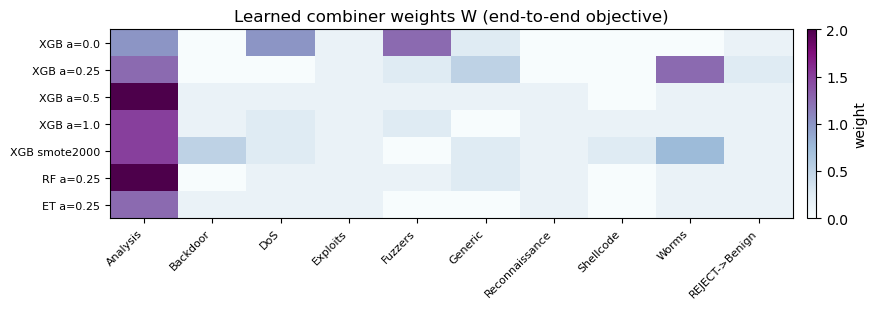

In [19]:
# --- objective 1: Stage-B 10-class macro-F1 ---
t0 = time.time()
sb_fn = lambda W: f1_score(ARM_R["y_ref"], fuse(ARM_R["P_ref"], Wclass=W).argmax(1),
                           average="macro", zero_division=0)
W_sb, sb_score = fit_W(ARM_R, sb_fn)
print("W (Stage-B objective) fitted in %.0fs -- Stage-B 10-class mF1 %.4f"
      % (time.time() - t0, sb_score))

# --- objective 2: end-to-end macro-F1 over the COMB half ---
gpos_comb = comb_idx[p_gate[comb_idx] > 0.5]
yt_gpos = y_arr[gpos_comb]
P_GPOS = [OOF10[m][gpos_comb] for m in range(M)]

neg_comb = comb_idx[p_gate[comb_idx] <= 0.5]
BG = np.zeros((10, 10), np.int64)                # gate-negatives: fixed background, all -> Benign
for c, cnt in zip(*np.unique(y_arr[neg_comb], return_counts=True)):
    BG[c, 0] = cnt

def e2e_fn(W):
    yp = LAB10[fuse(P_GPOS, Wclass=W).argmax(1)]     # reject index 9 -> label 0
    cm = np.bincount(yt_gpos * 10 + yp, minlength=100).reshape(10, 10) + BG
    return macro_f1_from_cm(cm)

print("\nCOMB gate-positives %d | fixed background rows %d" % (len(gpos_comb), len(neg_comb)))
t0 = time.time()
W_u, e_u = fit_W(ARM_R, e2e_fn)                      # cold start from uniform
W_w, e_w = fit_W(ARM_R, e2e_fn, W0=W_sb)             # warm start from the Stage-B solution
W_e2e = W_w if e_w >= e_u else W_u
print("W (end-to-end objective) fitted in %.0fs" % (time.time() - t0))
print("  COMB e2e mF1 -- uniform %.4f | W_stageB %.4f | W_e2e %.4f (%s start)"
      % (e2e_fn(np.ones((M, NCR)) / M), e2e_fn(W_sb), max(e_u, e_w),
         "warm" if e_w >= e_u else "cold"))
print("  reject column unchanged by the re-fit:", np.allclose(W_sb[:, IREJ], W_e2e[:, IREJ]),
      "-- the ascent rebalances the FAMILY columns instead")

plt.figure(figsize=(9, 3.2))
plt.imshow(W_e2e, cmap="BuPu", aspect="auto")
plt.colorbar(fraction=0.025, pad=0.02, label="weight")
plt.yticks(range(M), MODELS, fontsize=8)
plt.xticks(range(NCR), FAMR, rotation=45, ha="right", fontsize=8)
plt.title("Learned combiner weights W (end-to-end objective)")
plt.tight_layout()
plt.show()

### 4.5 Select the combination rule on SELV

21 candidate rules, scored end-to-end on the **SELV** half:

- 7 singles (each member alone, no fusion)
- 2 static (equal average; the learned per-class `W`)
- 7 pure dynamic (OLA at k in {30,100} x p in {1,3,8}; LCA at k=30)
- 5 hybrid (`W` combined with a dynamic term)

The family is **nested**: `Wclass=None` gives pure dynamic and `p=0` recovers pure static exactly, so
this is a parameter sweep rather than a bake-off between unrelated models.

The gate threshold is swept afterwards on the winner. Test is still untouched.

In [20]:
def rule_names():
    out = ["STATIC: equal average", "STATIC: per-class W"]
    out += ["single: " + m for m in MODELS]
    out += ["DYN OLA-cw k=%d p=%d" % (k, p) for k in (30, 100) for p in (1, 3, 8)]
    out += ["DYN LCA k=30"]
    out += ["HYBRID W x OLA-cw k=%d p=%d" % (k, p) for k in (30, 100) for p in (1, 3)]
    out += ["HYBRID W x LCA k=30 p=1"]
    return out

def rule_scores(st, P_g, idx, Wclass, name):
    """Fused score matrix for a named rule - the same maths as the rule list, without argmax."""
    if name.startswith("single: "):
        return P_g[MODELS.index(name[8:])]
    if name == "STATIC: equal average":
        return fuse(P_g, Wclass=np.ones((M, st["ncls"])) / M)
    if name == "STATIC: per-class W":
        return fuse(P_g, Wclass=Wclass)
    k = int(name.split("k=")[1].split()[0])
    p = float(name.split("p=")[1]) if "p=" in name else 1.0
    Wd = comp_lca(st, P_g, idx, k) if "LCA" in name else comp_ola(st, idx, k)
    return fuse(P_g, Wd=Wd, p=p, Wclass=(Wclass if name.startswith("HYBRID") else None))

def score_e2e(st, fam_g, ye, gmask, tag):
    yp = np.zeros(len(ye), int)
    if len(fam_g):
        yp[gmask] = st["LAB"][fam_g]
    return dict(rule=tag,
                mF1=round(f1_score(ye, yp, average="macro", zero_division=0), 4),
                mP=round(precision_score(ye, yp, average="macro", zero_division=0), 4),
                mR=round(recall_score(ye, yp, average="macro", zero_division=0), 4),
                acc=round(float((yp == ye).mean()), 4))

def selv_at(st, t):
    gmask = p_gate[selv_idx] > t
    gpos = selv_idx[gmask]
    P = [st["OOF"][m][gpos] for m in range(M)]
    _, idx = st["NN"].kneighbors(prof(P))
    return P, idx, gmask

t0 = time.time()
P, idx, gmask = selv_at(ARM_R, 0.5)
tab = pd.DataFrame([score_e2e(ARM_R, rule_scores(ARM_R, P, idx, W_e2e, r).argmax(1),
                              y_arr[selv_idx], gmask, r) for r in rule_names()]
                   ).sort_values("mF1", ascending=False).reset_index(drop=True)
print("--- SELV: 21 candidate rules at gate threshold 0.5 (%.0fs) ---" % (time.time() - t0))
print(tab.to_string(index=False))
WINNER = tab.iloc[0]["rule"]
print("\nSELV winner: %s  (%.4f)" % (WINNER, tab.iloc[0]["mF1"]))
del P, idx; gc.collect()

  File "C:\Users\night\miniconda3\envs\ai4beg\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\night\miniconda3\envs\ai4beg\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\night\miniconda3\envs\ai4beg\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\night\miniconda3\envs\ai4beg\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


--- SELV: 21 candidate rules at gate threshold 0.5 (6s) ---
                       rule    mF1     mP     mR    acc
 HYBRID W x OLA-cw k=30 p=3 0.6717 0.6996 0.6673 0.9859
    HYBRID W x LCA k=30 p=1 0.6710 0.7006 0.6652 0.9859
HYBRID W x OLA-cw k=100 p=3 0.6699 0.6973 0.6665 0.9858
 HYBRID W x OLA-cw k=30 p=1 0.6699 0.6987 0.6655 0.9859
HYBRID W x OLA-cw k=100 p=1 0.6693 0.6975 0.6655 0.9858
        STATIC: per-class W 0.6689 0.6968 0.6651 0.9859
        DYN OLA-cw k=30 p=8 0.6594 0.7361 0.6235 0.9873
        DYN OLA-cw k=30 p=3 0.6578 0.7389 0.6202 0.9873
       DYN OLA-cw k=100 p=8 0.6573 0.7385 0.6209 0.9873
       DYN OLA-cw k=100 p=1 0.6565 0.7351 0.6155 0.9872
       DYN OLA-cw k=100 p=3 0.6563 0.7328 0.6177 0.9873
        DYN OLA-cw k=30 p=1 0.6560 0.7305 0.6169 0.9872
      STATIC: equal average 0.6512 0.7275 0.6108 0.9871
               DYN LCA k=30 0.6506 0.7253 0.6106 0.9872
          single: XGB a=0.5 0.6487 0.6941 0.6221 0.9868
          single: RF a=0.25 0.6430 0.7415 0.

90

In [21]:
# Gate threshold sweep on the SELV winner only.
sweep = []
for t in (0.3, 0.4, 0.5, 0.6, 0.7):
    P, idx, gmask = selv_at(ARM_R, t)
    r = score_e2e(ARM_R, rule_scores(ARM_R, P, idx, W_e2e, WINNER).argmax(1),
                  y_arr[selv_idx], gmask, "t=%.1f" % t)
    r["t"] = t
    sweep.append(r)
    del P, idx; gc.collect()

sw = pd.DataFrame(sweep).sort_values("mF1", ascending=False).reset_index(drop=True)
print("--- gate threshold sweep on '%s' ---" % WINNER)
print(sw[["rule", "mF1", "mP", "mR", "acc"]].to_string(index=False))
FINAL_T = float(sw.iloc[0]["t"])
print("\nSELV-selected threshold : %.1f" % FINAL_T)
print("Spread across all five   : %.4f" % (sw["mF1"].max() - sw["mF1"].min()))
print("The threshold is a near-null lever once the reject class exists - it does the same job better.")

--- gate threshold sweep on 'HYBRID W x OLA-cw k=30 p=3' ---
 rule    mF1     mP     mR    acc
t=0.7 0.6734 0.7031 0.6638 0.9860
t=0.6 0.6731 0.7021 0.6666 0.9860
t=0.5 0.6717 0.6996 0.6673 0.9859
t=0.4 0.6708 0.6980 0.6680 0.9858
t=0.3 0.6700 0.6948 0.6700 0.9857

SELV-selected threshold : 0.7
Spread across all five   : 0.0034
The threshold is a near-null lever once the reject class exists - it does the same job better.


### 4.6 Refit on train + val

Selection is finished, so every component is refit on **all** 2,085,442 rows before test is touched.

Both pools are refit: the 10-class reject pool (the model being proposed) and the 9-class v7 pool
(the baseline it must beat). The paired comparison in 6.2 needs both scored on the same test rows.

In [22]:
t0 = time.time()
gate_f = fit_gate(X_trf, y_arr)
print("gate refit (%.1fm)" % ((time.time() - t0) / 60))

Xa9 = X_trf[att_trf].reset_index(drop=True)
FINAL9 = [fit_member(k, p, Xa9, pd.Series(fam_trf[att_trf]), NC) for _, (k, p) in SPECS]
print("9-class baseline pool refit (%.1fm)" % ((time.time() - t0) / 60))

m10 = yr10 >= 0
Xa10 = X_trf[m10].reset_index(drop=True)
FINAL10 = [fit_member(k, p, Xa10, pd.Series(yr10[m10]), NCR) for _, (k, p) in SPECS]
print("10-class reject pool refit (%.1fm total)" % ((time.time() - t0) / 60))

p_test = gate_f.predict_proba(X_test)[:, 1].astype(np.float32)
del Xa9, Xa10; gc.collect()
print("\nTest gate probabilities ready. Nothing has read y_te yet.")

gate refit (0.6m)


9-class baseline pool refit (2.3m)


10-class reject pool refit (4.6m total)



Test gate probabilities ready. Nothing has read y_te yet.


## 5. Model Evaluation
_Test Performance_

Same metric set as the DT / RF / XGBoost baselines so the comparison is direct. **Macro-F1 is the
primary metric** - every class counts equally, so Worms (49 test rows) weighs as much as Benign
(505,063).

### 5.1 Metrics

A note on **ROC-AUC**: this is a pipeline, not a single probabilistic classifier, so a 10-class
probability has to be constructed. It is built by soft routing - `P(family k) = p_att * q_k` and
`P(Benign) = (1 - p_att) + p_att * q_reject` - with gate-negative rows emitting a hard Benign,
exactly as the deployed system does. The AUC therefore reflects the gate's hard rejection as a
property of the architecture rather than papering over it.

In [23]:
gmask_t = p_test > FINAL_T
gpos_t = np.where(gmask_t)[0]
P_t = [m.predict_proba(X_test.iloc[gpos_t]).astype(np.float32) for m in FINAL10]
_, idx_t = ARM_R["NN"].kneighbors(prof(P_t))

S_t = rule_scores(ARM_R, P_t, idx_t, W_e2e, WINNER)
y_pred = np.zeros(len(y_te), int)
y_pred[gmask_t] = LAB10[S_t.argmax(1)]

# 10-class probability matrix for ROC-AUC, by soft routing through the same fused scores.
q = S_t / S_t.sum(1, keepdims=True)
pa = p_test[gpos_t]
y_proba = np.zeros((len(y_te), 10))
y_proba[:, 0] = 1.0                                        # gate-negatives: hard Benign
y_proba[gpos_t, 0] = (1 - pa) + pa * q[:, IREJ]
for k in range(NC):
    y_proba[gpos_t, attack_labels[k]] = pa * q[:, k]
y_proba = y_proba / y_proba.sum(1, keepdims=True)

print("Configuration : %s @ gate t=%.1f" % (WINNER, FINAL_T))
print("Accuracy      : %.4f" % accuracy_score(y_te, y_pred))
print("ROC-AUC       : %.4f   (macro, One-vs-Rest, soft-routed)\n"
      % roc_auc_score(y_te, y_proba, multi_class="ovr", average="macro"))

print("%-12s%10s%10s" % ("", "weighted", "macro"))
for name, metric in [("Precision", precision_score), ("Recall", recall_score), ("F1-score", f1_score)]:
    w = metric(y_te, y_pred, average="weighted", zero_division=0)
    mm = metric(y_te, y_pred, average="macro", zero_division=0)
    note = "   <- macro F1 = primary metric" if name == "F1-score" else ""
    print("%-12s%10.4f%10.4f%s" % (name, w, mm, note))

print()
print(classification_report(y_te, y_pred, labels=list(range(10)),
                            target_names=NAMES, digits=4, zero_division=0))

Configuration : HYBRID W x OLA-cw k=30 p=3 @ gate t=0.7
Accuracy      : 0.9867


ROC-AUC       : 0.9644   (macro, One-vs-Rest, soft-routed)

              weighted     macro
Precision       0.9880    0.7126
Recall          0.9867    0.6819
F1-score        0.9872    0.6873   <- macro F1 = primary metric

                precision    recall  f1-score   support

        Benign     0.9962    0.9936    0.9949    505063
      Analysis     0.0901    0.2597    0.1338        77
      Backdoor     0.8095    0.5667    0.6667        90
           DoS     0.6591    0.5554    0.6028       884
      Exploits     0.8046    0.8464    0.8250      6185
       Fuzzers     0.5725    0.7282    0.6410      5287
       Generic     0.8804    0.8765    0.8785       899
Reconnaissance     0.8855    0.7744    0.8262      2407
     Shellcode     0.8595    0.6262    0.7245       420
         Worms     0.5686    0.5918    0.5800        49

      accuracy                         0.9867    521361
     macro avg     0.7126    0.6819    0.6873    521361
  weighted avg     0.9880    0.9867    0.9872 

### 5.2 Confusion matrix

Raw counts across the 10 classes. Read the **Benign row** for false alarms and the **Benign column**
for attacks sent back as benign - those two cells are exactly what the reject class trades between.

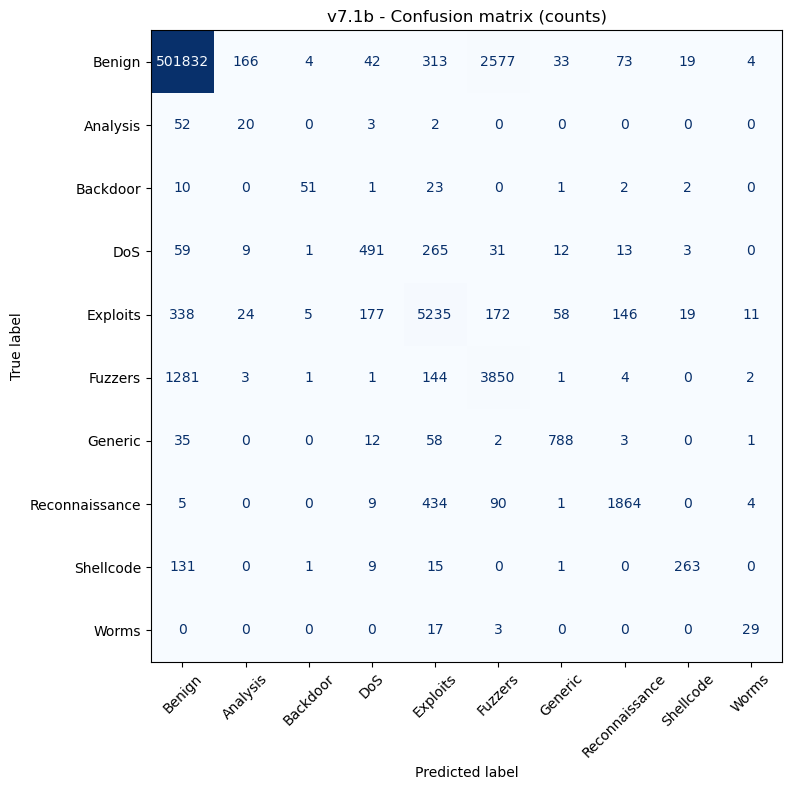

                Benign  Analysis  Backdoor  DoS  Exploits  Fuzzers  Generic  Reconnaissance  Shellcode  Worms
Benign          501832       166         4   42       313     2577       33              73         19      4
Analysis            52        20         0    3         2        0        0               0          0      0
Backdoor            10         0        51    1        23        0        1               2          2      0
DoS                 59         9         1  491       265       31       12              13          3      0
Exploits           338        24         5  177      5235      172       58             146         19     11
Fuzzers           1281         3         1    1       144     3850        1               4          0      2
Generic             35         0         0   12        58        2      788               3          0      1
Reconnaissance       5         0         0    9       434       90        1            1864          0      4
Shellcode 

In [24]:
cm = confusion_matrix(y_te, y_pred, labels=list(range(10)))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=NAMES).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False, values_format="d"
)
ax.set_title("v7.1b - Confusion matrix (counts)")
plt.tight_layout()
plt.show()

print(pd.DataFrame(cm, index=NAMES, columns=NAMES).to_string())

### 5.3 Reject-class accounting

The reject class is a **trade**, not a free win, and both sides must be reported together: flows
correctly sent back to Benign (false alarms cancelled) against real attacks sent back with them
(detections lost).

In [25]:
print("gate @%.1f           : attack recall %.4f | precision %.4f"
      % (FINAL_T, recall_score(att_te.astype(int), gmask_t.astype(int)),
         precision_score(att_te.astype(int), gmask_t.astype(int))))

n_leak = int(((y_te == 0) & (y_pred != 0)).sum())
n_rej = int((gmask_t & (y_pred == 0)).sum())
n_rej_ok = int((gmask_t & (y_pred == 0) & (y_te == 0)).sum())
alerts = int((y_pred != 0).sum())
true_alerts = int(((y_pred != 0) & (y_te != 0)).sum())

print("benign -> attack     : %d   (v7, without the reject class: 8,370)" % n_leak)
print("sent back to Benign  : %d" % n_rej)
print("   correctly (benign): %d   <- false alarms cancelled" % n_rej_ok)
print("   wrongly (attacks) : %d   <- detections lost, the price" % (n_rej - n_rej_ok))
print("\nSOC reading: %d alerts raised, %d genuine -> %.0f%% of alerts are false."
      % (alerts, true_alerts, 100 * (1 - true_alerts / max(alerts, 1))))

gate @0.7           : attack recall 0.9772 | precision 0.6833
benign -> attack     : 3231   (v7, without the reject class: 8,370)
sent back to Benign  : 5692
   correctly (benign): 4152   <- false alarms cancelled
   wrongly (attacks) : 1540   <- detections lost, the price

SOC reading: 17618 alerts raised, 14387 genuine -> 18% of alerts are false.


### 5.4 Explainability - what is explained, and how it is checked

Everything so far says *how well* the system classifies. 5.4-5.11 say *why* - and, unlike the
literature, each explanation is **verified** before it is read.

The object explained is the **deployed system itself** - the refit gate and the SELV-selected
combiner over all 7 members at the SELV-selected threshold - not a surrogate model.

| level | explains | space | verified by |
|---|---|---|---|
| **1** columns | gate + the 5 XGBoost Stage-B members, per column | log-odds | additivity; a 2nd independent implementation (`shap`) |
| **2** groups | the **fused 7-member score**, RF and ET included | probability | efficiency; reproduces the deployed decision |

**Level 2 is exact, not approximate.** Columns are grouped into four views - **SVC** (service
identity), **TIME**, **SIZE**, **FLAG** - so all 2^4 = 16 coalitions can be enumerated: no sampling.
And because Shapley values are linear while the combiner is

    S(x, c) = SUM_m  coef[x, m, c] * P_m(c | x)

the attribution of the fused score is exactly `SUM_m coef * phi(P_m)`. **Scope:** the per-instance
routing term inside `coef` is evaluated at `x` and held fixed - the standard treatment of a gated
mixture.

**Why groups and not 99 columns:** several derived columns are near-monotone rewrites of raw ones
(`frac_PSH` of `PSH Flag Count`), so how SHAP splits credit *between* them is arbitrary. Group
totals are not.

**Pre-registered** in `results/xai_treeshap/` (run at t=0.5), re-checked here at the SELV threshold:

| | prediction |
|---|---|
| P1 | additivity < 1e-3; two implementations agree < 1e-4; 100% decision reproduction |
| P2 | SVC leads Stage B; SVC does **not** lead the gate |
| P3 | in most overlap pairs the group pushing toward the wrong family is **not** SVC |
| P4 | deleting the top-5 SHAP columns hurts >= 2x more than deleting 5 random ones |
| P5 | under 0.002-IQR noise, where the decision holds: row Spearman >= 0.90 and top-5 Jaccard >= 0.60 |

### 5.5 Level 1 - exact column TreeSHAP, and the explain set

XGBoost computes exact (path-dependent) TreeSHAP natively via `pred_contribs`. Two checks:

- **additivity** - per row, the contributions plus the bias must equal the model's raw margin;
- **a second implementation** - `shap.TreeExplainer` is independent code; it must agree.

The **explain set** is drawn from test rows that pass the gate: up to 200 per true class (the
*stratified* part used for global summaries) plus up to 200 rows of each known confusion pair
(used in 5.8).

In [26]:
def view_of(c):
    """The v7.1e partition: disjoint and exhaustive over the 99 columns."""
    if c in SVC_COLS:
        return "SVC"
    lc = c.lower()
    if "flag" in lc or lc.startswith("frac_") or lc == "r_syn_fin":
        return "FLAG"
    if any(t in lc for t in ("iat", "duration", "active", "idle", "/s", "dur_per_pkt")):
        return "TIME"
    return "SIZE"

GROUPS = ("SVC", "TIME", "SIZE", "FLAG")
NG = len(GROUPS)
GOF = np.array([GROUPS.index(view_of(c)) for c in COLS])
GIDX = [np.where(GOF == g)[0] for g in range(NG)]
assert sum(len(v) for v in GIDX) == len(COLS)
print("groups:", ", ".join("%s %d" % (GROUPS[g], len(GIDX[g])) for g in range(NG)))

def contribs(model, Xdf):
    """Exact TreeSHAP from xgboost itself, plus the raw margin it has to add up to."""
    dm = xgb.DMatrix(Xdf)
    bst = model.get_booster()
    return bst.predict(dm, pred_contribs=True), bst.predict(dm, output_margin=True)

# --- explain set: gate-positive test rows ---
PAIRS = [(7, 4), (4, 7), (3, 4), (4, 3), (8, 5), (5, 8), (1, 4), (0, 5), (5, 0)]   # (true, predicted)
rng_x = np.random.RandomState(RS)
yt_g, yp_g = y_te[gpos_t], y_pred[gpos_t]
pick_s = [rng_x.choice(np.where(yt_g == c)[0], min(200, (yt_g == c).sum()), replace=False)
          for c in range(10)]
pick_p = [rng_x.choice(w, min(200, len(w)), replace=False)
          for w in [np.where((yt_g == a) & (yp_g == b))[0] for a, b in PAIRS]]
E_pos = np.unique(np.concatenate(pick_s + pick_p))         # positions inside gpos_t
STRAT = np.isin(E_pos, np.concatenate(pick_s))
E_test = gpos_t[E_pos]
Xe = X_test.iloc[E_test].reset_index(drop=True)
ye, ype = y_te[E_test], y_pred[E_test]
st = np.where(STRAT)[0]
print("explain set: %d gate-positive test rows (%d stratified)" % (len(Xe), len(st)))

# --- gate sample: 2,000 benign + 2,000 attack test rows ---
GATE_N = 2000
G_rows = np.concatenate([rng_x.choice(np.where(y_te == 0)[0], GATE_N, replace=False),
                         rng_x.choice(np.where(y_te != 0)[0], GATE_N, replace=False)])
Xg = X_test.iloc[G_rows].reset_index(drop=True)

# --- additivity on every XGBoost model ---
PHI_G, MG_G = contribs(gate_f, Xg)
ADD = {"gate": np.abs(PHI_G.sum(-1) - MG_G).max()}
XGB_MEMBERS = [i for i, (_, (k, _)) in enumerate(SPECS) if k in ("alpha", "smote")]
IDX_A25 = MODELS.index("XGB a=0.25")
PHI_M, MG_M = {}, {}
for m in XGB_MEMBERS:
    PHI_M[m], MG_M[m] = contribs(FINAL10[m], Xe)
    ADD[MODELS[m]] = np.abs(PHI_M[m].sum(-1) - MG_M[m]).max()

# --- second, independent implementation ---
sv_g = np.asarray(shap.TreeExplainer(gate_f).shap_values(Xg.iloc[:300]))
sv_m = np.asarray(shap.TreeExplainer(FINAL10[IDX_A25]).shap_values(Xe.iloc[:300]))   # (n, F, K)
XIMPL = {"gate": np.abs(sv_g - PHI_G[:300, :-1]).max(),
         "XGB a=0.25": np.abs(sv_m - np.transpose(PHI_M[IDX_A25][:300, :, :-1], (0, 2, 1))).max()}

print("\n%-16s %22s" % ("model", "max |sum phi - margin|"))
for k_, v in ADD.items():
    print("%-16s %22.2e" % (k_, v))
print("\nshap %s vs xgboost pred_contribs, max |difference|:" % shap.__version__,
      {k_: float(v) for k_, v in XIMPL.items()})
P1a = max(ADD.values()) < 1e-3
P1b = max(XIMPL.values()) < 1e-4

groups: SVC 25, TIME 25, SIZE 39, FLAG 10
explain set: 2622 gate-positive test rows (1585 stratified)



model            max |sum phi - margin|
gate                           1.91e-05
XGB a=0.0                      1.72e-05
XGB a=0.25                     1.62e-05
XGB a=0.5                      1.72e-05
XGB a=1.0                      1.72e-05
XGB smote2000                  1.81e-05

shap 0.51.0 vs xgboost pred_contribs, max |difference|: {'gate': 0.0, 'XGB a=0.25': 0.0}


### 5.6 Level 2 - exact group Shapley of the deployed fused score

`rule_coef` rewrites the selected combination rule as coefficients on the member probabilities.
It is checked against the notebook's own `rule_scores` on **every** gate-positive test row before
anything is attributed - if the rewrite were wrong, the explanation would be of a different model.

Absent groups are filled from a background of 40 Stage-B training rows (4 per class), averaged -
interventional Shapley, in probability space.

In [27]:
def rule_coef(st_, P_g, idx, Wclass, name):
    """The selected rule as S[n, c] = SUM_m coef[n, m, c] * P_m[n, c], routing fixed at x."""
    n, ncl = P_g[0].shape
    if name.startswith("single: "):
        cf = np.zeros((n, M, ncl)); cf[:, MODELS.index(name[8:]), :] = 1.0
        return cf
    if name == "STATIC: equal average":
        return np.full((n, M, ncl), 1.0 / M)
    if name == "STATIC: per-class W":
        return np.broadcast_to(Wclass[None], (n, M, ncl)).copy()
    k = int(name.split("k=")[1].split()[0])
    p = float(name.split("p=")[1]) if "p=" in name else 1.0
    Wd = comp_lca(st_, P_g, idx, k) if "LCA" in name else comp_ola(st_, idx, k)
    Wp = np.power(np.clip(Wd, 1e-6, None), p)
    Wp = Wp / Wp.sum(1, keepdims=True)
    cf = np.repeat(Wp[:, :, None], ncl, axis=2)
    return cf * Wclass[None] if name.startswith("HYBRID") else cf

def fused(P, cf):
    return np.einsum("nmc,mnc->nc", cf, np.stack(P).astype(np.float64))

COEF_t = rule_coef(ARM_R, P_t, idx_t, W_e2e, WINNER)
lin_err = np.abs(fused(P_t, COEF_t) - S_t).max()
print("linear rewrite of '%s' vs rule_scores, all %d gate-positive test rows: max |diff| %.1e"
      % (WINNER, len(gpos_t), lin_err))
assert lin_err < 1e-9

m10 = yr10 >= 0
i10, ya10 = np.where(m10)[0], yr10[m10]
rng_b = np.random.RandomState(RS)
BG_X = X_trf.iloc[np.concatenate([rng_b.choice(i10[ya10 == c], 4, replace=False)
                                  for c in range(NCR)])].values.astype(np.float32)
BG_P = [m.predict_proba(pd.DataFrame(BG_X, columns=COLS)).astype(np.float32).mean(0) for m in FINAL10]

def head_of(label):
    """Stage-B output index of a label: families 0..8, Benign -> the reject column."""
    return IREJ if label == 0 else fam_to_idx[label]

def group_shapley(Xdf, cf):
    """Exact interventional Shapley of the fused score over the 4 groups (all 16 coalitions).
    Returns phi (n, groups, classes), base value (n, classes) and S(x) (n, classes)."""
    n, B = len(Xdf), len(BG_X)
    Xn = Xdf.values.astype(np.float32)
    V = {(1 << NG) - 1: [m.predict_proba(Xdf).astype(np.float32) for m in FINAL10],
         0: [np.repeat(b[None], n, 0) for b in BG_P]}
    for mask in range(1, (1 << NG) - 1):
        absent = np.concatenate([GIDX[g] for g in range(NG) if not (mask >> g) & 1])
        rep = np.repeat(Xn, B, axis=0)
        rep[:, absent] = np.tile(BG_X[:, absent], (n, 1))
        rdf = pd.DataFrame(rep, columns=COLS)
        V[mask] = [m.predict_proba(rdf).astype(np.float32).reshape(n, B, -1).mean(1) for m in FINAL10]
    phi_m = np.zeros((M, n, NG, NCR))
    for g in range(NG):
        for mask in range(1 << NG):
            if (mask >> g) & 1:
                continue
            s_ = bin(mask).count("1")
            w_ = factorial(s_) * factorial(NG - s_ - 1) / factorial(NG)
            for m in range(M):
                phi_m[m, :, g, :] += w_ * (V[mask | (1 << g)][m] - V[mask][m])
    return np.einsum("nmc,mngc->ngc", cf, phi_m), fused(V[0], cf), fused(V[(1 << NG) - 1], cf)

t0 = time.time()
PHI, BASE_S, S_FULL = group_shapley(Xe, COEF_t[E_pos])
head_e = S_FULL.argmax(1)
eff = np.abs(PHI.sum(1) + BASE_S - S_FULL).max()
repro = (LAB10[head_e] == ype).mean()
print("group Shapley on %d rows x 16 coalitions x %d background rows: %.0fs"
      % (len(Xe), len(BG_X), time.time() - t0))
print("efficiency  max |sum phi + base - S(x)| = %.1e" % eff)
print("full coalition reproduces the deployed decision on %.4f%% of rows" % (100 * repro))
P1c = eff < 1e-6 and repro == 1.0

linear rewrite of 'HYBRID W x OLA-cw k=30 p=3' vs rule_scores, all 23310 gate-positive test rows: max |diff| 0.0e+00


group Shapley on 2622 rows x 16 coalitions x 40 background rows: 67s
efficiency  max |sum phi + base - S(x)| = 6.3e-09
full coalition reproduces the deployed decision on 100.0000% of rows


The last two numbers are guaranteed by the algebra - they are checks that the *code* is right, not
evidence about the model. The evidence-bearing checks are the additivity residuals and the
two-implementation agreement in 5.5, which is exactly what CyberAdaptAI's table cannot pass.

### 5.7 Where the evidence lives

Share of mean |SHAP| per group, against the column share (what a group would get if every column
counted equally) and against XGBoost's built-in **gain importance** - the number most papers report.

                             SVC   TIME   SIZE   FLAG
all columns (reference)    0.253  0.253  0.394  0.101
gate - SHAP                0.119  0.162  0.703  0.016
gate - gain importance     0.004  0.003  0.989  0.004
Stage B ensemble - SHAP    0.432  0.132  0.352  0.084
Stage B XGB a=0.25 - gain  0.640  0.039  0.249  0.072


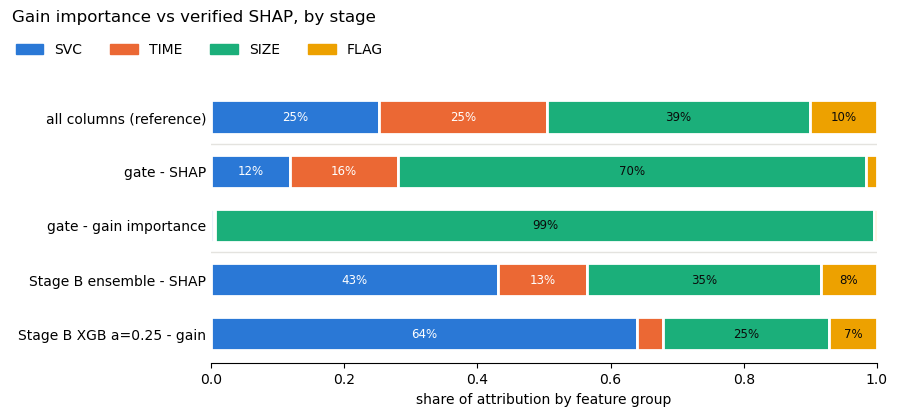

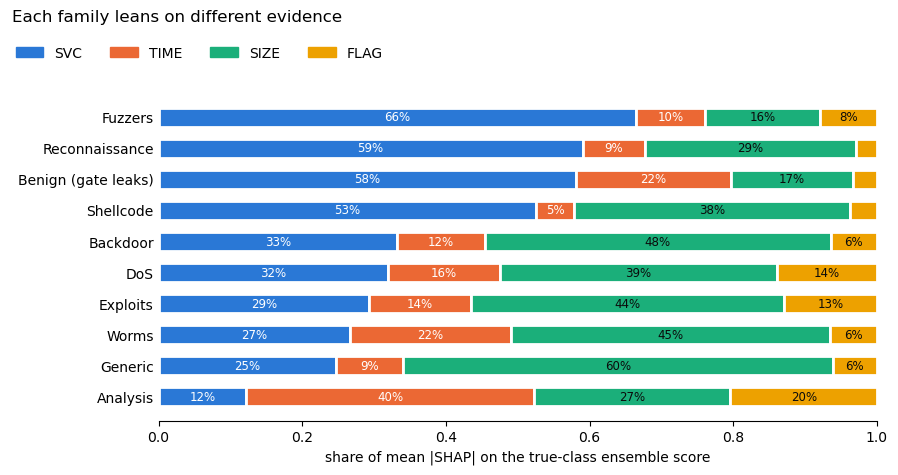


gate: Spearman(mean|SHAP|, gain) 0.585 | top-10 overlap 5/10
  top-5 SHAP: hdr_per_pkt_fwd, Fwd Seg Size Min, dst_port_num, Bwd Packets/s, Bwd Packet Length Min
  top-5 gain: Fwd Seg Size Min, Bwd Packet Length Min, hdr_per_pkt_fwd, bpp_bwd, Bwd Packet Length Mean

XGB a=0.25: Spearman(mean|SHAP|, gain) 0.426 | top-10 overlap 5/10
  top-5 SHAP: dst_port_num, svc_rpc, Total Length of Fwd Packet, svc_bgp, Bwd Packet Length Max
  top-5 gain: svc_rpc, svc_bgp, svc_smb, svc_http, frac_PSH


In [28]:
SURF, INK, INK2, GRIDC, NEUTRAL = "#ffffff", "#0b0b0b", "#52514e", "#e4e3df", "#a3a29c"
GC = {"SVC": "#2a78d6", "TIME": "#eb6834", "SIZE": "#1baf7a", "FLAG": "#eda100"}

def share(v):
    v = np.asarray(v, float)
    return v / v.sum()

def stacked_rows(ax, labels, rows):
    """100% stacked bars, 2px surface gaps, direct percentage labels."""
    yy = np.arange(len(labels))[::-1]
    for yi, row in zip(yy, rows):
        left = 0.0
        for g, v in zip(GROUPS, row):
            ax.barh(yi, v, left=left, height=0.62, color=GC[g], edgecolor=SURF, linewidth=2)
            if v >= 0.045:
                ax.text(left + v / 2, yi, "%d%%" % round(100 * v), ha="center", va="center",
                        fontsize=8.5, color=INK if g in ("SIZE", "FLAG") else "white")
            left += v
    ax.set_yticks(yy); ax.set_yticklabels(labels)
    ax.set_xlim(0, 1); ax.tick_params(axis="y", length=0)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)

def group_legend(fig, title):
    from matplotlib.patches import Patch
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    fig.legend(handles=[Patch(color=GC[g], label=g) for g in GROUPS], frameon=False, ncol=4,
               loc="upper left", bbox_to_anchor=(0.0, 0.93))

grp_gate = np.stack([PHI_G[:, GIDX[g]].sum(1) for g in range(NG)], 1)
SH = pd.DataFrame({
    "all columns (reference)": share([len(GIDX[g]) for g in range(NG)]),
    "gate - SHAP": share(np.abs(grp_gate).mean(0)),
    "gate - gain importance": share([gate_f.feature_importances_[GIDX[g]].sum() for g in range(NG)]),
    "Stage B ensemble - SHAP": share(np.abs(PHI[st, :, head_e[st]]).mean(0)),
    "Stage B XGB a=0.25 - gain": share([FINAL10[IDX_A25].feature_importances_[GIDX[g]].sum()
                                       for g in range(NG)]),
}, index=GROUPS).T
print(SH.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 4.2))
stacked_rows(ax, list(SH.index), SH.values)
for yy in (3.5, 1.5):
    ax.axhline(yy, color=GRIDC, lw=1)
ax.set_xlabel("share of attribution by feature group")
group_legend(fig, "Gain importance vs verified SHAP, by stage")
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

PC = {}
for c in range(10):
    w = st[ye[st] == c]
    if len(w):
        PC[NAMES[c] + (" (gate leaks)" if c == 0 else "")] = share(np.abs(PHI[w, :, head_of(c)]).mean(0))
PC = pd.DataFrame(PC, index=GROUPS).T.sort_values("SVC", ascending=False)
fig, ax = plt.subplots(figsize=(9, 4.8))
stacked_rows(ax, list(PC.index), PC.values)
ax.set_xlabel("share of mean |SHAP| on the true-class ensemble score")
group_legend(fig, "Each family leans on different evidence")
fig.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

AGREE = {}
for nm, phi_abs, gain in [
        ("gate", np.abs(PHI_G[:, :-1]).mean(0), gate_f.feature_importances_),
        ("XGB a=0.25", np.abs(PHI_M[IDX_A25][st, MG_M[IDX_A25][st].argmax(1), :-1]).mean(0),
         FINAL10[IDX_A25].feature_importances_)]:
    rho = spearmanr(phi_abs, gain).correlation
    ov = len(set(np.argsort(-phi_abs)[:10]) & set(np.argsort(-gain)[:10]))
    AGREE[nm] = rho
    print("\n%s: Spearman(mean|SHAP|, gain) %.3f | top-10 overlap %d/10" % (nm, rho, ov))
    print("  top-5 SHAP:", ", ".join(COLS[i] for i in np.argsort(-phi_abs)[:5]))
    print("  top-5 gain:", ", ".join(COLS[i] for i in np.argsort(-gain)[:5]))
P2 = SH.loc["Stage B ensemble - SHAP"].idxmax() == "SVC" and SH.loc["gate - SHAP"].idxmax() != "SVC"

**Reading.** Gain importance counts how much a column's splits reduce the training loss; SHAP
measures how much a column moves the *prediction* for actual flows. They disagree sharply here, so
**quote SHAP shares** - and any earlier "svc carries 70% of importance" figure is a *gain* figure.
Service identity still leads family attribution, while the attack/benign gate leans on size and
length - "which service" does not say "malicious".

### 5.8 The overlap pairs - what pushes a row toward the wrong family

For a row of true family *a* predicted as *b*:

    D_g = phi_g(S_b) - phi_g(S_a)

Positive D means group *g* pushes the row toward the **wrong** class. Each panel compares confused
rows with correctly classified rows of the same true family (the control, which should sit at or
below zero). `REJECT` means the row was routed back to Benign by the reject class.

Shellcode -> Fuzzers     n=0  (fewer than 15 confused rows - not evaluated)
Fuzzers -> Shellcode     n=0  (fewer than 15 confused rows - not evaluated)
Analysis -> Exploits     n=2  (fewer than 15 confused rows - not evaluated)

             pair   n driver  D_SVC  D_TIME  D_SIZE  D_FLAG  top%_SVC  top%_TIME  top%_SIZE  top%_FLAG
Recon -> Exploits 224    SVC 0.0173  0.0137  0.0122 -0.0026      52.2       18.3       29.5        0.0
Exploits -> Recon 146   SIZE 0.0069  0.0078  0.0179  0.0061       0.0       39.0       57.5        3.4
  DoS -> Exploits 214   SIZE 0.0157  0.0112  0.0310  0.0121      22.0       11.2       51.9       15.0
  Exploits -> DoS 177   SIZE 0.0177  0.0103  0.0266 -0.0043      24.9       31.6       39.0        4.5
Benign -> Fuzzers 260    SVC 0.0612 -0.0033  0.0156  0.0121      69.2        5.0       18.1        7.7
Fuzzers -> REJECT 242   TIME 0.0172  0.0328  0.0060 -0.0084      20.2       71.5        8.3        0.0


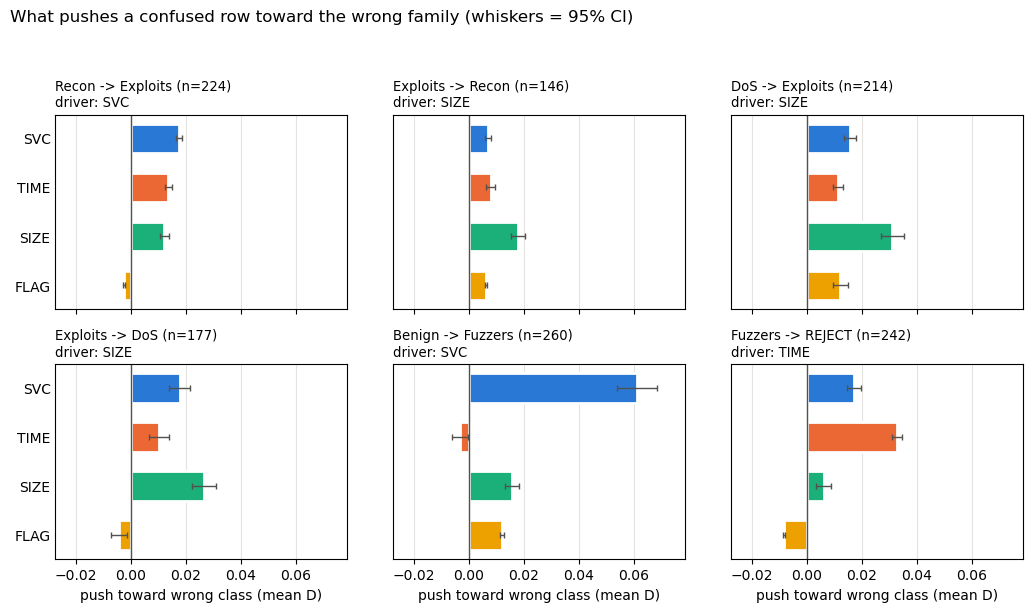

In [29]:
short =lambda n: n.replace("Reconnaissance", "Recon")
PAIR_ROWS = []
for a, b in PAIRS:
    conf = np.where((ye == a) & (ype == b))[0]
    ctrl = np.where((ye == a) & (ype == a))[0]
    name = "%s -> %s" % (short(NAMES[a]), "REJECT" if b == 0 else short(NAMES[b]))
    if len(conf) < 15:
        print("%-24s n=%d  (fewer than 15 confused rows - not evaluated)" % (name, len(conf)))
        continue
    D = PHI[conf][:, :, head_of(b)] - PHI[conf][:, :, head_of(a)]
    Dc = PHI[ctrl][:, :, head_of(b)] - PHI[ctrl][:, :, head_of(a)]
    mu, ci = D.mean(0), 1.96 * D.std(0, ddof=1) / np.sqrt(len(conf))
    PAIR_ROWS.append(dict(pair=name, n=len(conf), driver=GROUPS[int(mu.argmax())], mu=mu, ci=ci,
                          top=np.bincount(D.argmax(1), minlength=NG) / len(conf),
                          ctrl=Dc.mean(0) if len(ctrl) else np.full(NG, np.nan)))

print()
print(pd.DataFrame([dict(pair=r["pair"], n=r["n"], driver=r["driver"],
                         **{"D_" + g: round(r["mu"][i], 4) for i, g in enumerate(GROUPS)},
                         **{"top%_" + g: round(100 * r["top"][i], 1) for i, g in enumerate(GROUPS)})
                    for r in PAIR_ROWS]).to_string(index=False))

nc_ = 3; nr_ = int(np.ceil(len(PAIR_ROWS) / nc_))
fig, axes = plt.subplots(nr_, nc_, figsize=(10.5, 2.8 * nr_ + 0.6), sharex=True, sharey=True,
                         squeeze=False)
xmax = max(float((r["mu"] + r["ci"]).max()) for r in PAIR_ROWS) * 1.15
for ax, r in zip(axes.flat, PAIR_ROWS):
    yy = np.arange(NG)[::-1]
    for yi, g in zip(yy, range(NG)):
        ax.barh(yi, r["mu"][g], height=0.6, color=GC[GROUPS[g]], edgecolor=SURF, linewidth=2)
        ax.errorbar(r["mu"][g], yi, xerr=r["ci"][g], fmt="none", ecolor=INK2, elinewidth=1, capsize=2.5)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(yy); ax.set_yticklabels(GROUPS); ax.tick_params(axis="y", length=0)
    ax.set_xlim(-0.35 * xmax, xmax)
    ax.grid(axis="x", color=GRIDC, lw=0.8); ax.set_axisbelow(True)
    ax.set_title("%s (n=%d)\ndriver: %s" % (r["pair"], r["n"], r["driver"]), loc="left", fontsize=9.5)
for ax in list(axes.flat)[len(PAIR_ROWS):]:
    ax.set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("push toward wrong class (mean D)")
fig.suptitle("What pushes a confused row toward the wrong family (whiskers = 95% CI)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()
P3 = len(PAIR_ROWS) > 0 and sum(r["driver"] != "SVC" for r in PAIR_ROWS) > len(PAIR_ROWS) / 2

**Reading.**

- **The Exploits / DoS / Recon triangle is a SIZE problem** - SIZE drives three of its four
  directions (byte and length profiles overlap); only Recon -> Exploits is led by SVC.
- **The Fuzzers sink runs through different evidence in each direction.** Benign flows that leak
  into Fuzzers are pulled by **SVC** (they sit on Fuzzers' services; top driver on ~69% of rows),
  while real Fuzzers swallowed by the reject class are pushed by **TIME** (~72% of rows). Two
  mechanisms, which is why the reject class could only move this error, not remove it (5.3).
- **Shellcode <-> Fuzzers no longer appears at all** - zero confusions in either direction. Service
  identity dissolved the pair that used to be the project's worst overlap; that absence is a result.
- Controls (correctly classified rows) sit below zero, as they should.

### 5.9 Faithfulness - do the top features actually matter?

An explanation is only useful if the features it ranks highest really drive the output. Delete the
top-k SHAP columns of each row (set to the training median) and measure the drop in the explained
margin; compare with deleting k **random** columns. Median replacement is off-manifold - but the
random arm has the same defect, so the **ratio** is the fair quantity.

model         k      top-k   random-k   ratio
gate          1     7.0551     0.3016   23.4x
gate          3    16.1510     0.8915   18.1x
gate          5    16.7065     1.4650   11.4x
gate         10    18.2733     2.9128    6.3x
XGB a=0.25    1     2.9455     0.0956   30.8x
XGB a=0.25    3     4.7168     0.2411   19.6x
XGB a=0.25    5     5.0615     0.4170   12.1x
XGB a=0.25   10     5.5209     0.7886    7.0x


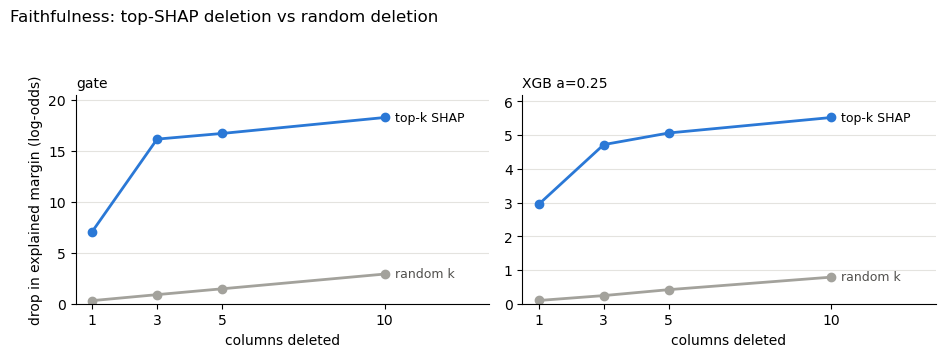

In [30]:
MED_ALL = X_trf.sample(300_000, random_state=RS).median().values.astype(np.float32)
MED_B = X_trf[m10].median().values.astype(np.float32)
KS = (1, 3, 5, 10)

def deletion(model, Xdf, phi, cls, med, reps=5):
    """Mean margin drop: top-k SHAP columns vs k random columns -> median."""
    Xn = Xdf.values.astype(np.float32); n, F_ = Xn.shape
    bst = model.get_booster()
    marg = lambda A: bst.predict(xgb.DMatrix(pd.DataFrame(A, columns=COLS)), output_margin=True)
    pickm = (lambda mg: mg) if cls is None else (lambda mg: mg[np.arange(n), cls])
    base = pickm(marg(Xn))
    order = np.argsort(-phi, axis=1)
    res = {}
    for k in KS:
        A = Xn.copy(); cols = order[:, :k]; A[np.arange(n)[:, None], cols] = med[cols]
        top = float((base - pickm(marg(A))).mean())
        rnd = []
        for r_ in range(reps):
            cols = np.argsort(np.random.RandomState(RS + r_).rand(n, F_), axis=1)[:, :k]
            A = Xn.copy(); A[np.arange(n)[:, None], cols] = med[cols]
            rnd.append(float((base - pickm(marg(A))).mean()))
        res[k] = (top, float(np.mean(rnd)))
    return res

ga = GATE_N + np.where(MG_G[GATE_N:] > 0)[0]                     # attack rows the gate fires on
pc = MG_M[IDX_A25][st].argmax(1)
FAITH = {"gate": deletion(gate_f, Xg.iloc[ga], PHI_G[ga, :-1], None, MED_ALL),
         "XGB a=0.25": deletion(FINAL10[IDX_A25], Xe.iloc[st], PHI_M[IDX_A25][st, pc, :-1], pc, MED_B)}

print("%-11s %3s %10s %10s %7s" % ("model", "k", "top-k", "random-k", "ratio"))
for nm, d in FAITH.items():
    for k in KS:
        print("%-11s %3d %10.4f %10.4f %6.1fx" % (nm, k, d[k][0], d[k][1], d[k][0] / d[k][1]))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))
for ax, (nm, d) in zip(axes, FAITH.items()):
    top, rnd = [d[k][0] for k in KS], [d[k][1] for k in KS]
    ax.plot(KS, top, color=GC["SVC"], lw=2, marker="o", ms=6)
    ax.plot(KS, rnd, color=NEUTRAL, lw=2, marker="o", ms=6)
    ax.text(KS[-1] + 0.3, top[-1], "top-k SHAP", va="center", fontsize=9)
    ax.text(KS[-1] + 0.3, rnd[-1], "random k", va="center", fontsize=9, color=INK2)
    ax.set_xticks(KS); ax.set_xlim(0.5, KS[-1] + 3.2); ax.set_ylim(0, max(top) * 1.12)
    ax.set_title(nm, loc="left", fontsize=10); ax.set_xlabel("columns deleted")
    ax.grid(axis="y", color=GRIDC, lw=0.8); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel("drop in explained margin (log-odds)")
fig.suptitle("Faithfulness: top-SHAP deletion vs random deletion", x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()
P4 = all(d[5][0] / d[5][1] >= 2.0 for d in FAITH.values())

### 5.10 Stability - is the explanation as brittle as the prediction?

The robustness series (`robustness_chapter.md`) found the *predictions* brittle: undirected noise of
0.002 IQR already costs ~0.13 macro-F1. Here the same noise - free columns at the full budget,
packet/byte/flag counts at half, service identity frozen, integers rounded, CICFlowMeter identities
repaired and all derived columns recomputed - is applied to the explained rows, and the column
SHAP vectors are compared with the same rebuild at **zero** noise - `repair()` recomputes five
model-input columns slightly differently from CICFlowMeter (`results/v73j_repair_confound/`), and
that recomputation must not be counted as noise. Rows whose decision **flips** are reported
separately: the question is whether explanations move even where the prediction holds.

In [31]:
COSTLY_PREFIX = ("Total Fwd Packet", "Total Bwd packets", "Total Length of Fwd Packet",
                 "Total Length of Bwd Packet", "FIN Flag", "SYN Flag", "RST Flag", "PSH Flag",
                 "ACK Flag", "Fwd PSH", "Fwd URG", "Bwd URG", "URG Flag", "CWR Flag", "ECE Flag",
                 "Bwd PSH")

def repair(F_):
    """Recompute the CICFlowMeter columns that are functions of others, so a perturbed flow stays
    physically consistent."""
    F_ = F_.copy(); has = lambda c: c in F_.columns
    fpk, bpk = F_["Total Fwd Packet"], F_["Total Bwd packets"]
    fby, bby = F_["Total Length of Fwd Packet"], F_["Total Length of Bwd Packet"]
    dur_s = F_["Flow Duration"] / 1e6
    tot_pk, tot_by = fpk + bpk, fby + bby
    for c, v in [("Down/Up Ratio", safe(bpk, fpk)), ("Flow Packets/s", safe(tot_pk, dur_s)),
                 ("Fwd Packets/s", safe(fpk, dur_s)), ("Bwd Packets/s", safe(bpk, dur_s)),
                 ("Average Packet Size", safe(tot_by, tot_pk)), ("Packet Length Mean", safe(tot_by, tot_pk)),
                 ("Flow Bytes/s", safe(tot_by, dur_s)), ("Fwd Segment Size Avg", safe(fby, fpk)),
                 ("Bwd Segment Size Avg", safe(bby, bpk))]:
        if has(c):
            F_[c] = v
    num = F_.select_dtypes(include=[np.number]).columns
    F_[num] = F_[num].clip(lower=0.0)
    return F_

def perturb(test_pos, budget):
    F0 = FULL_te.iloc[test_pos].reset_index(drop=True)
    S0 = SVC_te.iloc[test_pos].reset_index(drop=True)
    rs = np.random.RandomState(RS); F_ = F0.copy()
    for c in RAW_COLS:
        cap = budget * IQR[c] * (0.5 if c.startswith(COSTLY_PREFIX) else 1.0)
        F_[c] = F0[c].values + rs.uniform(-cap, cap, len(F0)).astype(np.float32)
    for c in INT_COLS: F_[c] = np.round(F_[c].values)
    F_ = repair(F_)
    for c in INT_COLS: F_[c] = np.round(F_[c].values)
    return pd.concat([F_[BASE_COLS].astype(np.float32), derive(F_)[DER_COLS], S0], axis=1)[COLS]

# Reference = the SAME rebuild at zero noise. repair() recomputes 5 model-input columns slightly
# differently from CICFlowMeter (results/v73j_repair_confound/), so comparing against the original
# flows would mix that recomputation into the noise effect.

def row_spearman(A, B_):
    ra, rb = rankdata(A, axis=1), rankdata(B_, axis=1)
    ra -= ra.mean(1, keepdims=True); rb -= rb.mean(1, keepdims=True)
    return (ra * rb).sum(1) / np.sqrt((ra ** 2).sum(1) * (rb ** 2).sum(1) + 1e-12)

def jacc5(A, B_):
    ta, tb = np.argsort(-np.abs(A), 1)[:, :5], np.argsort(-np.abs(B_), 1)[:, :5]
    return np.array([len(set(x) & set(z)) / len(set(x) | set(z)) for x, z in zip(ta, tb)])

REF_G, REF_GM = contribs(gate_f, perturb(G_rows[ga], 0.0))
REF_B, REF_BM = contribs(FINAL10[IDX_A25], perturb(E_test[st], 0.0))
pc0 = REF_BM.argmax(1)
print("zero-noise rebuild vs original: gate decision changed on %.4f of rows, member argmax on %.4f\n"
      % (((REF_GM > 0) != (MG_G[ga] > 0)).mean(), (pc0 != pc).mean()))

STAB = []
for b in (0.002, 0.02):
    ph, mg = contribs(gate_f, perturb(G_rows[ga], b))
    flip = (mg > 0) != (REF_GM > 0)
    A0, A1 = REF_G[:, :-1], ph[:, :-1]
    ph2, mg2 = contribs(FINAL10[IDX_A25], perturb(E_test[st], b))
    flip2 = mg2.argmax(1) != pc0
    B0, B1 = REF_B[np.arange(len(st)), pc0, :-1], ph2[np.arange(len(st)), pc0, :-1]
    for nm, fl, a0, a1 in [("gate", flip, A0, A1), ("XGB a=0.25", flip2, B0, B1)]:
        r_, j_ = row_spearman(a0, a1), jacc5(a0, a1)
        STAB.append(dict(model=nm, budget=b, flip_rate=round(fl.mean(), 4),
                         spearman_held=round(np.median(r_[~fl]), 4),
                         jaccard5_held=round(np.median(j_[~fl]), 4),
                         spearman_flipped=round(np.median(r_[fl]), 4) if fl.any() else np.nan,
                         jaccard5_flipped=round(np.median(j_[fl]), 4) if fl.any() else np.nan))
STAB = pd.DataFrame(STAB)
print(STAB.to_string(index=False))
s2 = STAB[STAB.budget == 0.002]
P5 = bool((s2.spearman_held >= 0.90).all() and (s2.jaccard5_held >= 0.60).all())

zero-noise rebuild vs original: gate decision changed on 0.0000 of rows, member argmax on 0.0088



     model  budget  flip_rate  spearman_held  jaccard5_held  spearman_flipped  jaccard5_flipped
      gate   0.002     0.0460         0.8570         0.6667            0.5727            0.4286
XGB a=0.25   0.002     0.1685         0.8828         0.6667            0.7053            0.4286
      gate   0.020     0.0930         0.7428         0.6667            0.5097            0.4286
XGB a=0.25   0.020     0.2864         0.7736         0.6667            0.6340            0.4286


### 5.11 Pre-registered verdicts

In [32]:
VERDICTS = pd.DataFrame([
    ("P1a", "additivity < 1e-3 on every XGBoost model", P1a),
    ("P1b", "shap and xgboost agree < 1e-4", P1b),
    ("P1c", "group efficiency < 1e-6, 100% decision reproduction", P1c),
    ("P2", "SVC leads Stage B, not the gate", P2),
    ("P3", "non-SVC driver in most overlap pairs", P3),
    ("P4", "top-5 deletion >= 2x random", P4),
    ("P5", "explanations stable where predictions hold (0.002 IQR)", P5),
], columns=["id", "prediction", "supported"])
VERDICTS["verdict"] = np.where(VERDICTS["supported"], "SUPPORTED", "REFUTED")
print(VERDICTS[["id", "prediction", "verdict"]].to_string(index=False))

 id                                             prediction   verdict
P1a               additivity < 1e-3 on every XGBoost model SUPPORTED
P1b                          shap and xgboost agree < 1e-4 SUPPORTED
P1c    group efficiency < 1e-6, 100% decision reproduction SUPPORTED
 P2                        SVC leads Stage B, not the gate SUPPORTED
 P3                   non-SVC driver in most overlap pairs SUPPORTED
 P4                            top-5 deletion >= 2x random SUPPORTED
 P5 explanations stable where predictions hold (0.002 IQR)   REFUTED


**Reading.** Six of seven pre-registered predictions hold, the same as the standalone run in
`results/xai_treeshap/` (t=0.5) - so the conclusions do not depend on the gate threshold.

**P5 is refuted, and it stays refuted with the cleaner zero-noise reference used here.** Where the
decision does not flip, the top of the explanation mostly survives (median top-5 Jaccard 0.667: four
of five columns kept), but the full ranking moves (median row Spearman ~0.86-0.88 vs the 0.90 bar).
Part of that is an instrument effect - ranks among near-zero contributions are noise. The honest
phrasing: **the top of an explanation is mostly stable under small measurement noise; the full
ranking is not.** Never "SHAP is unstable".

## 6. Model Improvement
_Fine-tune & Optimize_

### 6.1 The improvement ladder

Three configurations, all scored on the same test rows: the v7 nine-class baseline (with its own
combiner fitted the same way, so the comparison is fair), the reject class under the Stage-B
objective, and the reject class under the end-to-end objective.

baseline-arm W fitted in 14s (Stage-B 9-class mF1 0.7626)



         configuration  macro_F1  macro_P  macro_R  accuracy
v7    9-class baseline    0.6608   0.6434   0.7549    0.9799
  v7.1  + reject class    0.6843   0.7164   0.6744    0.9875
 v7.1b + e2e objective    0.6874   0.7111   0.6874    0.9866
 FINAL (SELV-selected)    0.6873   0.7126   0.6819    0.9867


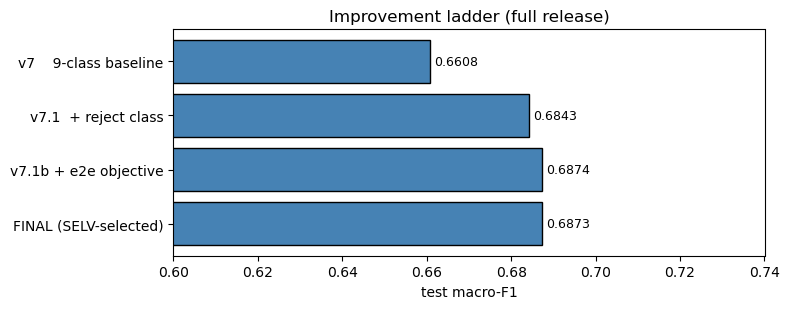

In [33]:
# Baseline arm gets its own combiner, fitted by the same procedure on the same COMB rows.
t0 = time.time()
b_fn = lambda W: f1_score(ARM_B["y_ref"], fuse(ARM_B["P_ref"], Wclass=W).argmax(1),
                          average="macro", zero_division=0)
W_base, b_score = fit_W(ARM_B, b_fn)
print("baseline-arm W fitted in %.0fs (Stage-B 9-class mF1 %.4f)" % (time.time() - t0, b_score))

def test_predict(st, POOL, Wclass, rule, t):
    gm = p_test > t
    gp = np.where(gm)[0]
    Pp = [m.predict_proba(X_test.iloc[gp]).astype(np.float32) for m in POOL]
    _, ix = st["NN"].kneighbors(prof(Pp))
    yp = np.zeros(len(y_te), int)
    yp[gm] = st["LAB"][rule_scores(st, Pp, ix, Wclass, rule).argmax(1)]
    return yp

yp_v7 = test_predict(ARM_B, FINAL9, W_base, WINNER, 0.5)

gm5 = p_test > 0.5
gp5 = np.where(gm5)[0]
P5 = [m.predict_proba(X_test.iloc[gp5]).astype(np.float32) for m in FINAL10]
_, ix5 = ARM_R["NN"].kneighbors(prof(P5))
yp_v71 = np.zeros(len(y_te), int)
yp_v71[gm5] = LAB10[rule_scores(ARM_R, P5, ix5, W_sb, WINNER).argmax(1)]
yp_v71b = np.zeros(len(y_te), int)
yp_v71b[gm5] = LAB10[rule_scores(ARM_R, P5, ix5, W_e2e, WINNER).argmax(1)]

rows = []
for tag, yp in [("v7    9-class baseline", yp_v7),
                ("v7.1  + reject class", yp_v71),
                ("v7.1b + e2e objective", yp_v71b),
                ("FINAL (SELV-selected)", y_pred)]:
    rows.append(dict(configuration=tag,
                     macro_F1=round(f1_score(y_te, yp, average="macro", zero_division=0), 4),
                     macro_P=round(precision_score(y_te, yp, average="macro", zero_division=0), 4),
                     macro_R=round(recall_score(y_te, yp, average="macro", zero_division=0), 4),
                     accuracy=round(accuracy_score(y_te, yp), 4)))
ladder = pd.DataFrame(rows)
print()
print(ladder.to_string(index=False))

plt.figure(figsize=(8, 3.2))
b = plt.barh(ladder["configuration"], ladder["macro_F1"], color="steelblue", edgecolor="black")
plt.bar_label(b, fmt="%.4f", fontsize=9, padding=3)
plt.xlim(0.60, 0.74)
plt.xlabel("test macro-F1")
plt.title("Improvement ladder (full release)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 6.2 Paired bootstrap

A point estimate says nothing on its own. Resample the test set 2,000 times, stratified by class, and
score **both** configurations on the **same** resample each round so shared luck cancels.

The working rule for this project: **differences under about +/-0.012 macro-F1 are not meaningful**
on this test set. A result counts only when its whole interval clears zero.

In [34]:
def paired_bootstrap(yp_a, yp_b, n_boot=2000, seed=RS):
    code_a = y_te * 10 + yp_a
    code_b = y_te * 10 + yp_b
    rng = np.random.RandomState(seed)
    cls_i = [np.where(y_te == c)[0] for c in range(10)]
    diffs = np.empty(n_boot); marg = np.empty(n_boot)
    for it in range(n_boot):
        bidx = np.concatenate([ci[rng.randint(0, len(ci), len(ci))] for ci in cls_i])
        cma = np.bincount(code_a[bidx], minlength=100).reshape(10, 10)
        cmb = np.bincount(code_b[bidx], minlength=100).reshape(10, 10)
        fb = macro_f1_from_cm(cmb); marg[it] = fb
        diffs[it] = fb - macro_f1_from_cm(cma)
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    p = 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())
    return diffs.mean(), lo, hi, min(1.0, p), np.percentile(marg, [2.5, 97.5])

for tag, a, b in [("reject vs 9-class baseline", yp_v7, yp_v71),
                  ("e2e objective vs Stage-B objective", yp_v71, yp_v71b),
                  ("FINAL vs 9-class baseline", yp_v7, y_pred)]:
    dd, lo, hi, p, mci = paired_bootstrap(a, b)
    print("%-36s %+.4f  95%% CI [%+.4f, %+.4f]  p ~ %.3f   %s"
          % (tag, dd, lo, hi, p, "ESTABLISHED" if lo > 0 else "not established"))

mf = f1_score(y_te, y_pred, average="macro", zero_division=0)
_, _, _, _, mci = paired_bootstrap(yp_v7, y_pred)
print("\nHEADLINE macro-F1 %.4f, 95%% CI [%.4f, %.4f]" % (mf, mci[0], mci[1]))
print("Quote as %.3f [%.3f, %.3f] -- never four decimals for a single configuration."
      % (mf, mci[0], mci[1]))

fa = f1_score(y_te, yp_v7, average=None, labels=range(10), zero_division=0)
fb_ = f1_score(y_te, y_pred, average=None, labels=range(10), zero_division=0)
ra = recall_score(y_te, yp_v7, average=None, labels=range(10), zero_division=0)
rb = recall_score(y_te, y_pred, average=None, labels=range(10), zero_division=0)
print("\nper-class F1 (v7 baseline -> final), with final recall:")
for i, n in enumerate(NAMES):
    print("  %-16s F1 %.4f -> %.4f  (%+.4f) | R %.4f -> %.4f"
          % (n, fa[i], fb_[i], fb_[i] - fa[i], ra[i], rb[i]))

reject vs 9-class baseline           +0.0235  95% CI [+0.0143, +0.0328]  p ~ 0.000   ESTABLISHED


e2e objective vs Stage-B objective   +0.0032  95% CI [+0.0019, +0.0047]  p ~ 0.000   ESTABLISHED


FINAL vs 9-class baseline            +0.0266  95% CI [+0.0173, +0.0363]  p ~ 0.000   ESTABLISHED



HEADLINE macro-F1 0.6873, 95% CI [0.6702, 0.7032]
Quote as 0.687 [0.670, 0.703] -- never four decimals for a single configuration.

per-class F1 (v7 baseline -> final), with final recall:
  Benign           F1 0.9915 -> 0.9949  (+0.0034) | R 0.9834 -> 0.9936
  Analysis         F1 0.1619 -> 0.1338  (-0.0281) | R 0.5844 -> 0.2597
  Backdoor         F1 0.6710 -> 0.6667  (-0.0043) | R 0.5778 -> 0.5667
  DoS              F1 0.5663 -> 0.6028  (+0.0366) | R 0.5486 -> 0.5554
  Exploits         F1 0.8009 -> 0.8250  (+0.0241) | R 0.9015 -> 0.8464
  Fuzzers          F1 0.5981 -> 0.6410  (+0.0429) | R 0.9427 -> 0.7282
  Generic          F1 0.8792 -> 0.8785  (-0.0007) | R 0.8988 -> 0.8765
  Reconnaissance   F1 0.8201 -> 0.8262  (+0.0061) | R 0.7748 -> 0.7744
  Shellcode        F1 0.5057 -> 0.7245  (+0.2188) | R 0.7857 -> 0.6262
  Worms            F1 0.6136 -> 0.5800  (-0.0336) | R 0.5510 -> 0.5918


### 6.3 Levers tested and closed

For completeness, and because "did you tune it?" is the first question an examiner asks. Every
capacity-side lever in this project has now been tested and **none is established**. Gains came only
from weighting, information, and objectives.

| Lever | Where | Outcome |
|---|---|---|
| alpha weighting (0.25 over `balanced`) | `two_stage_stageB_weighting.ipynb` | **+0.0385, established** |
| Derived ratio features | `feature_engineering.ipynb` | **+0.0101, established** |
| Service identity (port / protocol) | `results/cic_unsw_svc/` | **+0.0982, established** |
| Hierarchy + reject class | this notebook | **+0.0242, established** |
| End-to-end combiner objective | this notebook | **+0.0032, established** |
| Full SMOTE balancing | `xgboost_model.ipynb` Stage 6 | worse (-0.072) |
| Focal / dynamic weighting | `two_stage_stageB_weighting.ipynb` | worse; collapses at gamma=2 |
| Algorithm-diverse ensemble pool | `two_stage_stageB_des.ipynb` | null |
| Per-class thresholds, soft routing | `two_stage_thresholds.ipynb` | null - redundant with `W` |
| Gate re-weighting and gate threshold | `two_stage_gate_weighting.ipynb` | null (+0.0006) |
| Wider alpha grid (1.5, 2.0) | `two_stage_stageB_ensemble_v3.ipynb` | null - the axis saturates at 1.0 |
| Second-round feature algebra (D2) | `feature_engineering_v2.ipynb` | null, for 38 extra columns |
| **XGBoost hyperparameter sweep** | `results/v72_hparam/` | **+0.0054, CI crosses zero - NOT established** |
| Reject-set enrichment | `results/v71c_reject_enrich/` | null (+0.0009) |
| TTL from the original UNSW files | `results/ttl_join/` | rejected - a label proxy, not behaviour |

The last two rows matter most for the write-up. Hyperparameter tuning **looks** like a bigger win
than the end-to-end objective (+0.0054 vs +0.0032) and is the one that cannot be claimed - its
interval crosses zero. And TTL was excluded *despite raising the score*, because it encodes which
machine generated the traffic rather than what the traffic did.

## 7. Prediction
_Deployment & Inference_

What deployment actually requires, beyond the fitted models:

1. the refit gate and the 7-member reject pool,
2. the 7x10 weight matrix `W`,
3. the **k-NN reference set** - the COMB probability profiles held in memory, needed by the dynamic
   term,
4. **for explanations**: the 40-row SHAP background set (`BG_X`).

Item 3 is the real cost of a dynamic combiner. The static variant needs only one small matrix
multiply; if inference budget were tight, `STATIC: per-class W` gives up very little (see the SELV
table in 4.5) and drops the reference set entirely.

`explain_flows` adds what an analyst needs next to an alert: which evidence group pushed the flow
to its predicted class, and the gate's strongest columns. It uses the same exact machinery as 5.6,
so each explanation passes the efficiency check. Cost: 16 x 40 extra predictions per **alerted**
flow - affordable per alert, not per packet. 5.10 is the caveat to ship with it: the top of an
explanation is mostly stable under small measurement noise, the full ranking is not.

In [35]:
def classify_flows(X_new, threshold=None):
    """Full v7.1b inference path for new flows.

    X_new : DataFrame with the same 99 columns, in the same order, as X_trf.
    returns: predicted label, class name, and the gate's attack probability.
    """
    t = FINAL_T if threshold is None else threshold
    pa = gate_f.predict_proba(X_new)[:, 1]
    gm = pa > t
    out = np.zeros(len(X_new), int)                       # gate-negatives stay Benign
    if gm.any():
        gp = np.where(gm)[0]
        Pn = [m.predict_proba(X_new.iloc[gp]).astype(np.float32) for m in FINAL10]
        _, ixn = ARM_R["NN"].kneighbors(prof(Pn))
        # reject index 9 maps to label 0, so a rejected flow is reported as Benign
        out[gm] = LAB10[rule_scores(ARM_R, Pn, ixn, W_e2e, WINNER).argmax(1)]
    return pd.DataFrame({
        "predicted_label": out,
        "predicted_class": [LABELS[i] for i in out],
        "gate_p_attack":   np.round(pa, 4),
    }, index=X_new.index)

# Demonstrate on a stratified handful of held-out flows.
demo_rows = np.concatenate([np.where(y_te == c)[0][:2] for c in range(10)])
demo = classify_flows(X_test.iloc[demo_rows])
demo.insert(0, "true_class", [LABELS[i] for i in y_te[demo_rows]])
demo["correct"] = demo["true_class"] == demo["predicted_class"]
print(demo.to_string())
print("\ncorrect on this stratified sample: %d / %d" % (demo["correct"].sum(), len(demo)))

           true_class  predicted_label predicted_class  gate_p_attack  correct
0              Benign                0          Benign         0.0000     True
1              Benign                0          Benign         0.0000     True
10158        Analysis                0          Benign         0.7844    False
32319        Analysis                0          Benign         0.3740    False
11874        Backdoor                2        Backdoor         0.9904     True
13778        Backdoor                4        Exploits         0.9948    False
292               DoS                3             DoS         0.9602     True
528               DoS                4        Exploits         0.9988    False
151          Exploits                3             DoS         0.9988    False
373          Exploits                4        Exploits         0.9978     True
53            Fuzzers                5         Fuzzers         0.9936     True
193           Fuzzers                5         Fuzze

In [36]:
def explain_flows(X_new, threshold=None, top=3):
    """Prediction + verified explanation for each flow.

    stageB_* : group contributions to the fused score of the PREDICTED class (rows that passed the
               gate); 'driver' is the largest one. Gate-negative rows have no Stage-B explanation.
    gate_top : the gate's three strongest columns, signed toward its decision.
    """
    t = FINAL_T if threshold is None else threshold
    res = classify_flows(X_new, t)
    phg, mgg = contribs(gate_f, X_new)
    sign = np.where(mgg > 0, 1.0, -1.0)[:, None]
    res["gate_top"] = [", ".join(COLS[j] for j in np.argsort(-(sign[i] * phg[i, :-1]))[:top])
                       for i in range(len(X_new))]
    for g in GROUPS:
        res["stageB_" + g] = np.nan
    res["driver"] = ""
    gm = res["gate_p_attack"].values > t
    if gm.any():
        gp = np.where(gm)[0]
        Pn = [m.predict_proba(X_new.iloc[gp]).astype(np.float32) for m in FINAL10]
        _, ixn = ARM_R["NN"].kneighbors(prof(Pn))
        phi, base, S = group_shapley(X_new.iloc[gp], rule_coef(ARM_R, Pn, ixn, W_e2e, WINNER))
        assert np.abs(phi.sum(1) + base - S).max() < 1e-6
        h = S.argmax(1)
        contrib = phi[np.arange(len(gp)), :, h]
        for gi, g in enumerate(GROUPS):
            res.iloc[gp, res.columns.get_loc("stageB_" + g)] = np.round(contrib[:, gi], 4)
        res.iloc[gp, res.columns.get_loc("driver")] = [GROUPS[j] for j in contrib.argmax(1)]
    return res

ex = explain_flows(X_test.iloc[demo_rows])
ex.insert(0, "true_class", [LABELS[i] for i in y_te[demo_rows]])
with pd.option_context("display.width", 250, "display.max_colwidth", 70):
    print(ex.drop(columns=["predicted_label"]).to_string())

           true_class predicted_class  gate_p_attack                                                       gate_top  stageB_SVC  stageB_TIME  stageB_SIZE  stageB_FLAG driver
0              Benign          Benign         0.0000          hdr_per_pkt_fwd, Fwd Seg Size Min, FWD Init Win Bytes         NaN          NaN          NaN          NaN       
1              Benign          Benign         0.0000               hdr_per_pkt_fwd, Fwd Seg Size Min, Bwd Packets/s         NaN          NaN          NaN          NaN       
10158        Analysis          Benign         0.7844                     Fwd Seg Size Min, hdr_per_pkt_fwd, svc_bgp      0.0047       0.0325       0.0462       0.0051   SIZE
32319        Analysis          Benign         0.3740                   cv_bwd_len, asym_byte, Fwd Packet Length Max         NaN          NaN          NaN          NaN       
11874        Backdoor        Backdoor         0.9904          Fwd Seg Size Min, Packet Length Mean, hdr_per_pkt_fwd      0.0474   

### Summary

The full-release ladder, every step selected on SELV and measured once on test:

**0.6601** (v7, nine classes) -> **+0.0242** reject class -> **+0.0032** end-to-end combiner
objective.

Two things to carry into the write-up:

**The reject class is an operating choice, not a fix.** It cancels several thousand false alarms and
loses a smaller number of real detections with them. The Fuzzers/Benign boundary is genuinely
inseparable in this representation - the reject class only decides which side pays. Report both
columns of 5.3 together, never the favourable one alone.

**Fit the combiner on the deployment objective, not the sub-problem objective.** The end-to-end refit
changes no architecture and adds no parameters, and it is established at p < 0.001. That is a clean,
general lesson that costs nothing to apply anywhere else.

**Explanations are verified, not asserted - and that, not "we add SHAP", is the XAI contribution.**
Every XGBoost explanation adds up to its model's output, two independent TreeSHAP implementations
agree, and the group explanation of the full ensemble reproduces every deployed decision. What they
show: gain importance overstates the leading feature group at both stages; service identity leads
family attribution but not detection; and the Fuzzers sink runs through *different* evidence in each
direction (service identity pulls benign leaks in, timing pushes real Fuzzers into the reject class)
- which is why no single lever fixed both sides. Ship explanations with the 5.10 caveat: the top of
an explanation survives small measurement noise, the full ranking does not.
